# PZT spatial fields

This notebook calculates statistics and generates actual PDF, SVG and 600-dpi
PNG figures through reusable functions. Spatial calibration (5.05 um/pixel)
and pulse separation (25 us) are user-confirmed. Stored-array units, axial
orientation, flags and the processing/export convention remain unverified.
Plots are therefore explicitly uncalibrated native-component diagnostics.
No filtering, gap filling or extrapolation is applied.


In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'RAW_data').exists():
    if root == root.parent:
        raise RuntimeError('Workspace root not found')
    root = root.parent
sys.path.insert(0, str(root))
from PZT_Atomiser_Analysis.analysis.pipeline import run
results = run(root / 'PZT_Atomiser_Analysis/config/analysis.json')


Calculating Batch4_Cam1


Validated [{'row': 0, 'column': 0, 'N': 1757, 'passed': True}, {'row': 159, 'column': 40, 'N': 1757, 'passed': True}, {'row': 318, 'column': 79, 'N': 1757, 'passed': True}]


Saved 24 figures in PDF, SVG, 600-dpi PNG and NPZ.


## Definitions and validation

Both components use paired finite samples; denominator N is used for RMS and
covariance. No flag meanings are inferred. All current u/v pairs are finite,
so finite support does not establish quality acceptance. Saved U/V match means
of us/vs, not u/v. The current analysis recomputes all moments from u/v.
Independent point checks, variance and correlation bounds, and the mean-speed
inequality are checked before plotting. Contours mask any grid cell touching
a missing node. Full-range limits are shared across configured conditions;
instantaneous limits are shared across selected frames. The first, middle and
last numeric field keys are selected without implying phase or typicality.


Batch4_Cam1 {
  "frames": 1757,
  "frame_keys": [
    "1",
    "1757"
  ],
  "shape": [
    319,
    80
  ],
  "grid_spacing_native": [
    64.0,
    -16.0
  ],
  "parameters": {
    "Lc": 1.0,
    "NumberOfFields": 1757,
    "Uc": 1.0,
    "Xorigin": 0.0,
    "Yorigin": 0.0,
    "calib": 0,
    "dt": 1.0,
    "nondim": 0,
    "nx": 80,
    "ny": 319,
    "scale": 1.0,
    "stats": 1,
    "viscosity": 1.0
  },
  "independent_point_checks": [
    {
      "row": 0,
      "column": 0,
      "N": 1757,
      "passed": true
    },
    {
      "row": 159,
      "column": 40,
      "N": 1757,
      "passed": true
    },
    {
      "row": 318,
      "column": 79,
      "N": 1757,
      "passed": true
    }
  ],
  "stored_statistics_max_absolute_difference": {
    "native_u": 0.15796313982289334,
    "native_v": 0.5165216043447409,
    "alternate_us": 0.0,
    "alternate_vs": 0.0
  },
  "flag_counts_total": {
    "0": 1097567,
    "1": 43741073
  },
  "local_N_range": [
    1757,
    1757
  ],

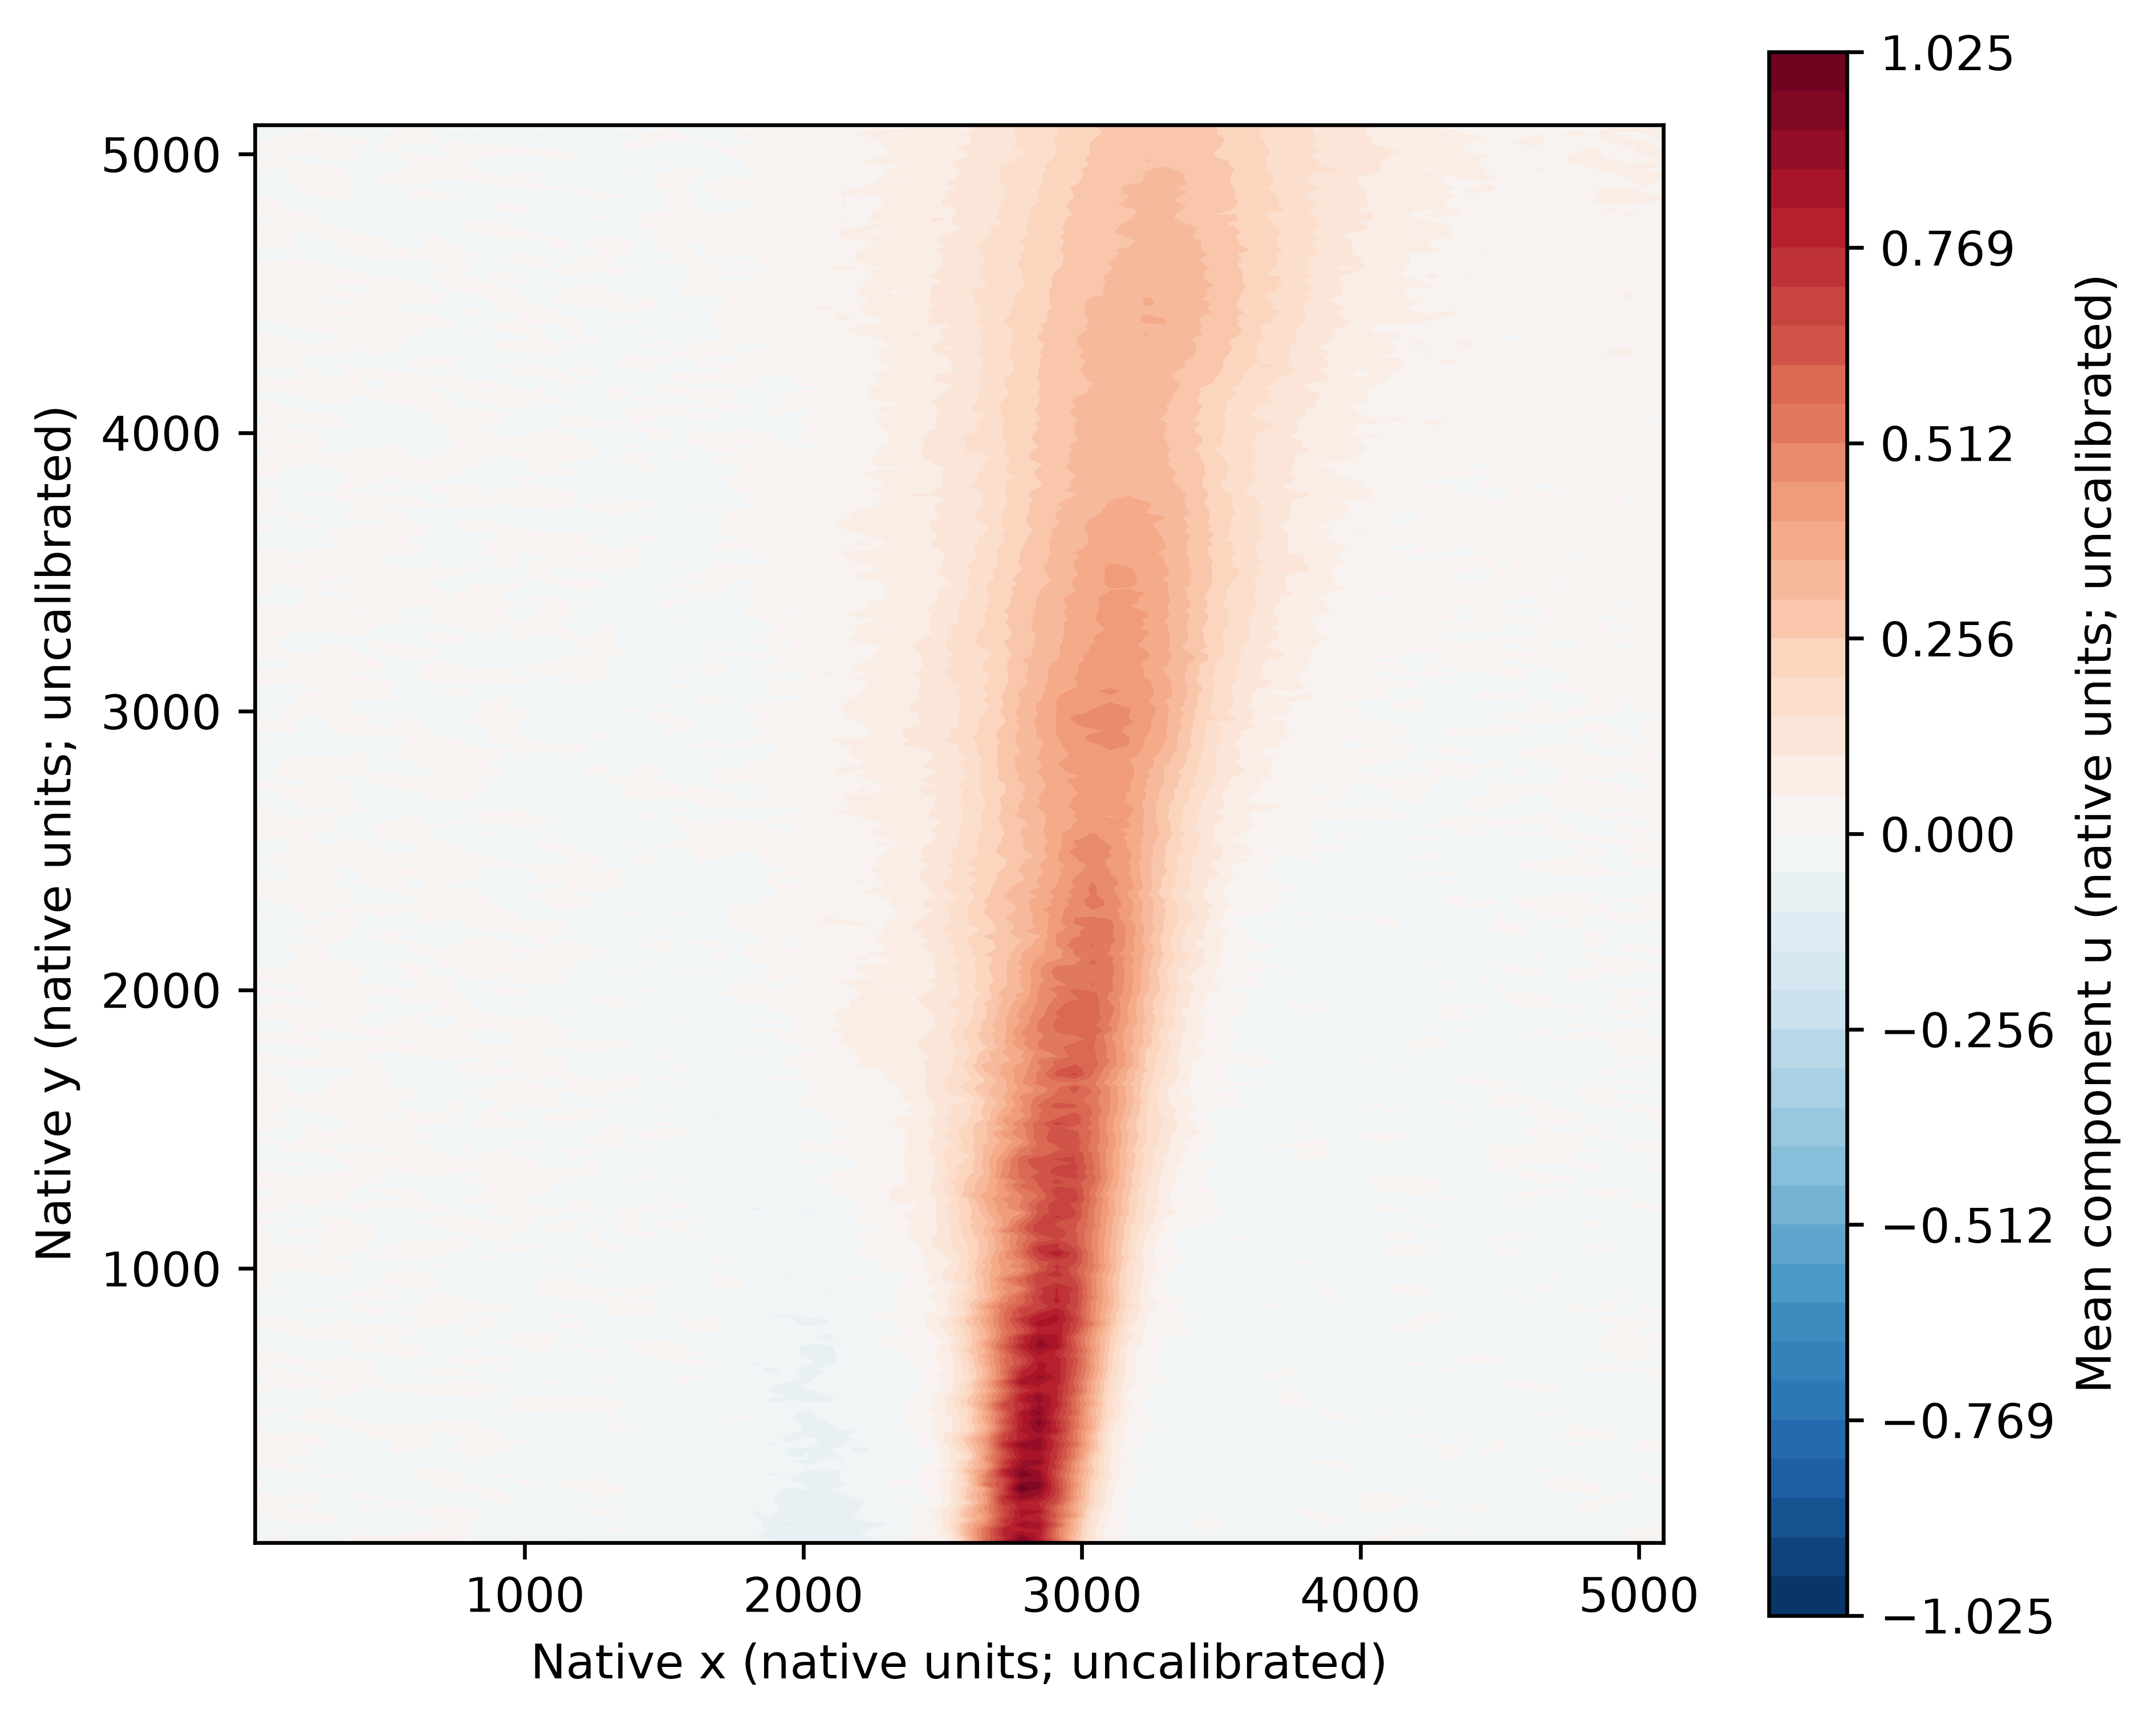

mean_v


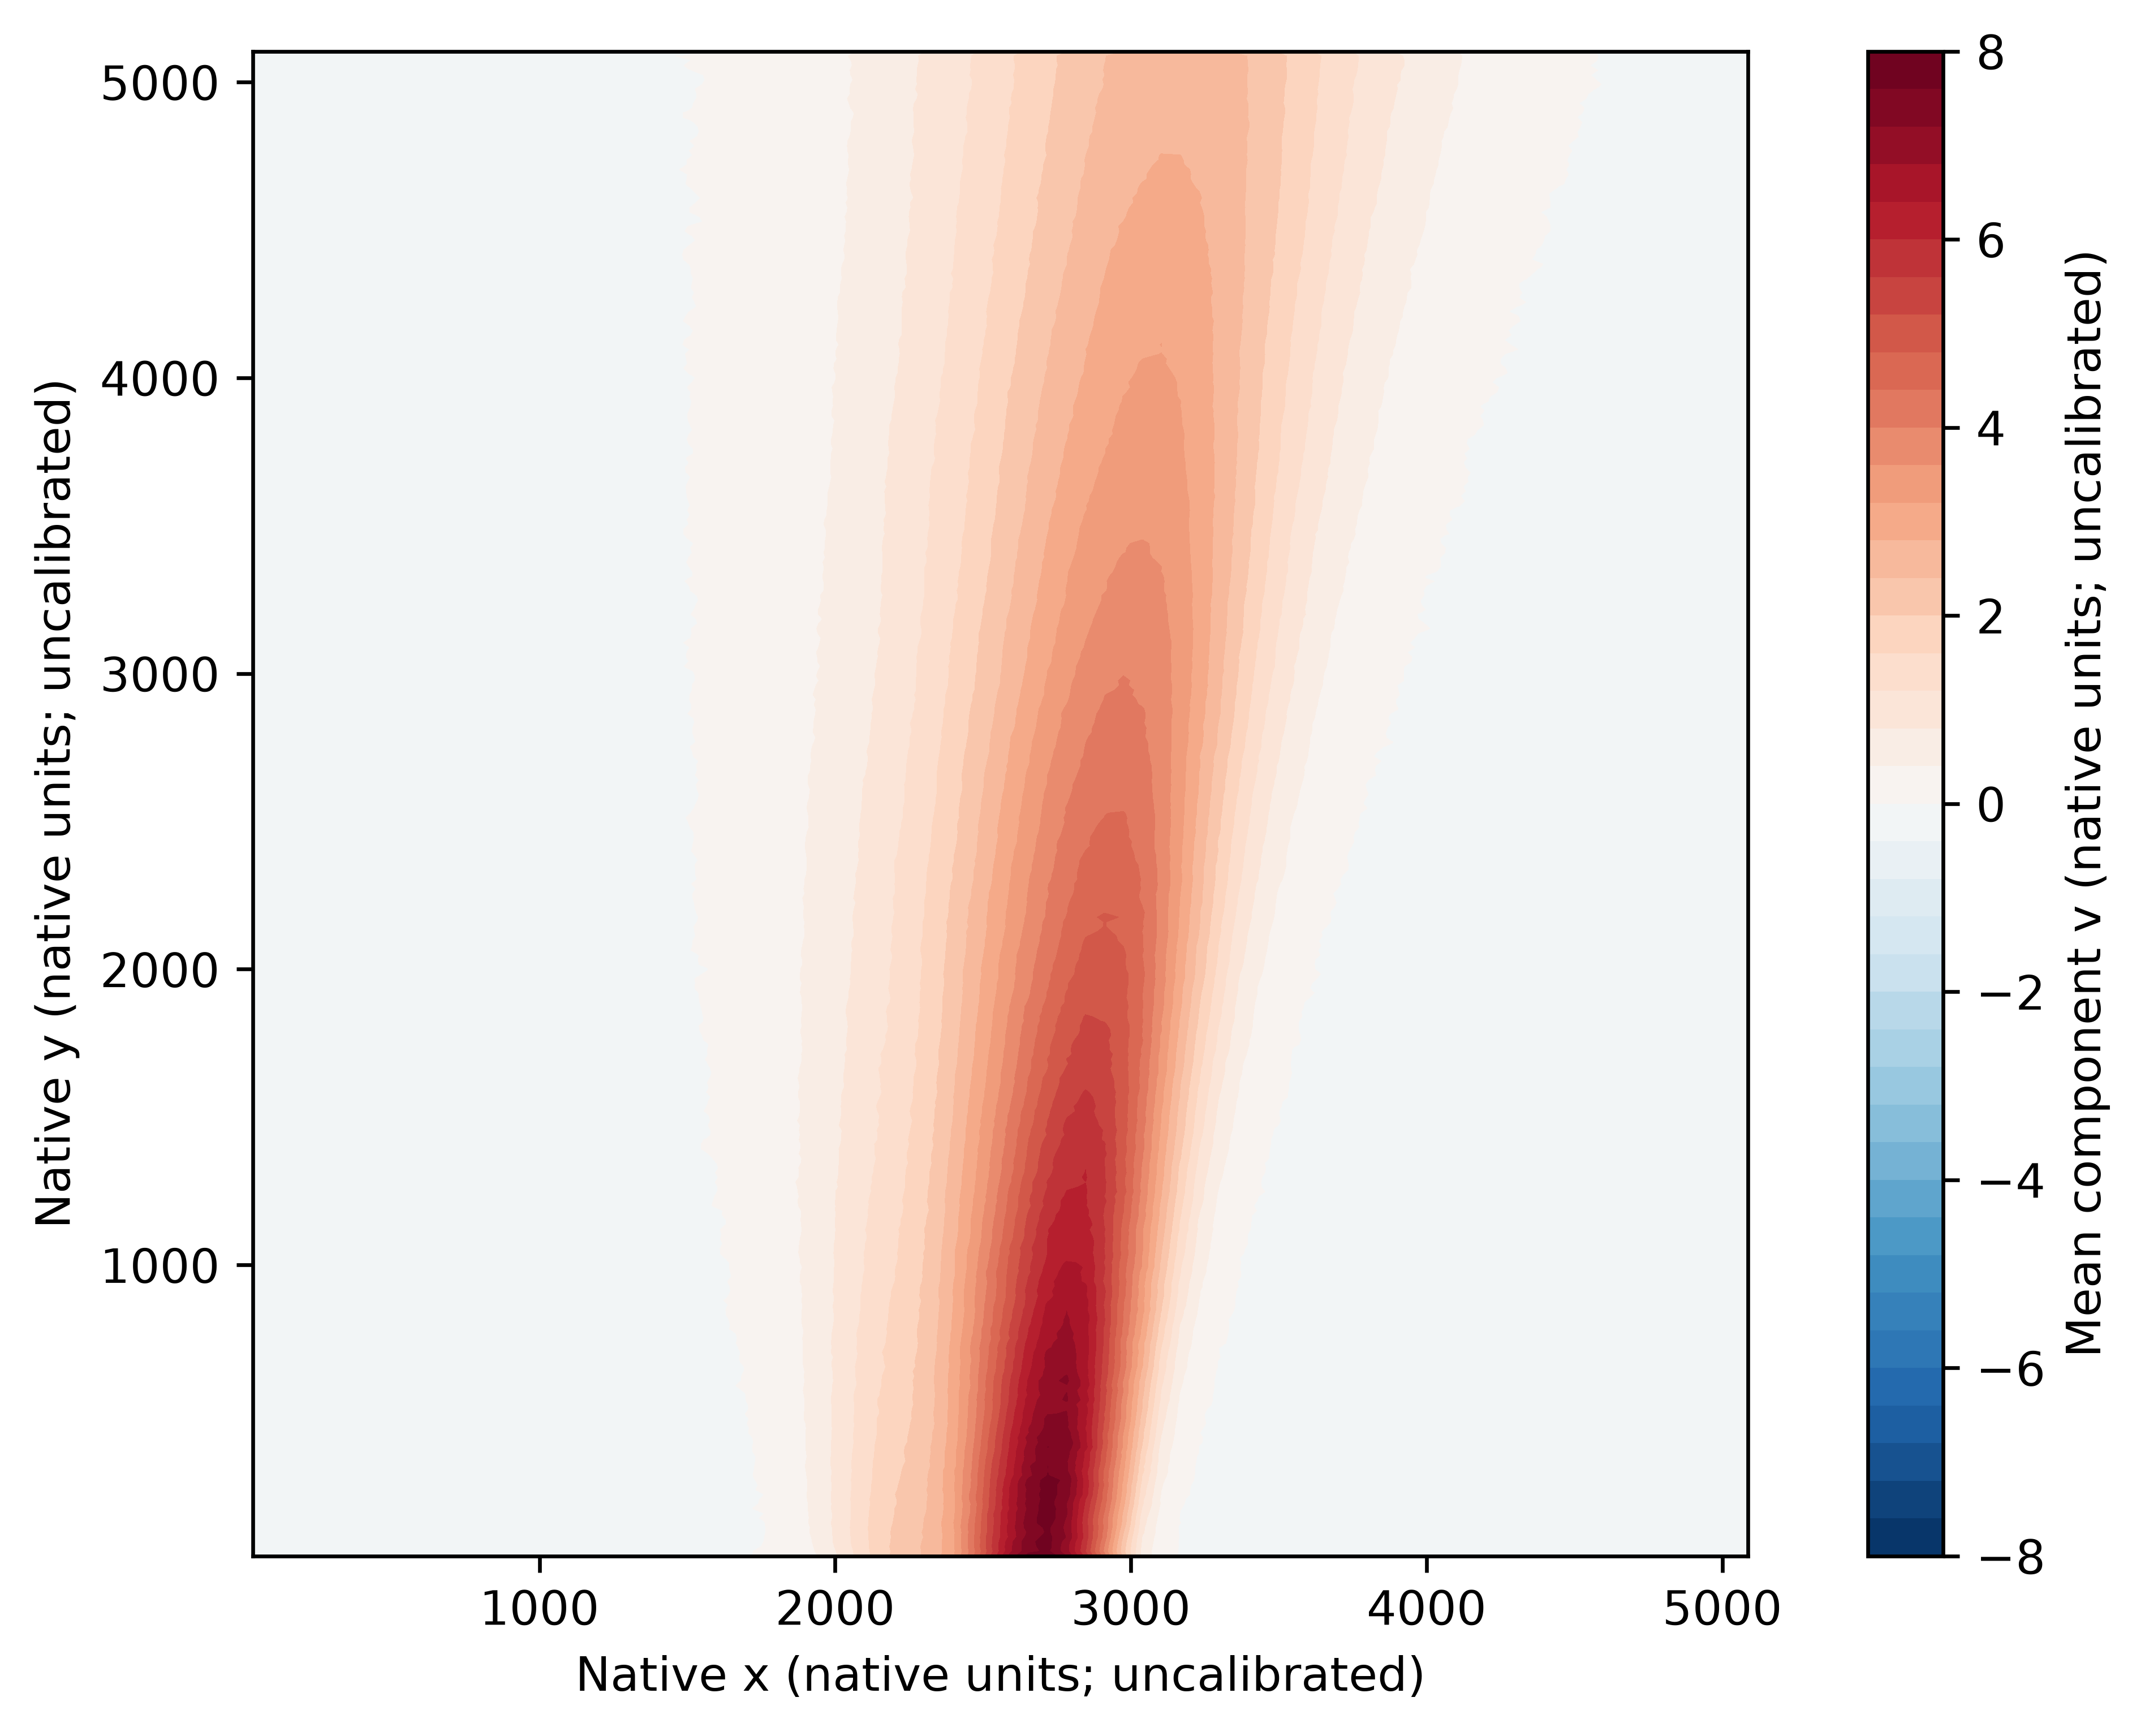

magnitude_mean_vector


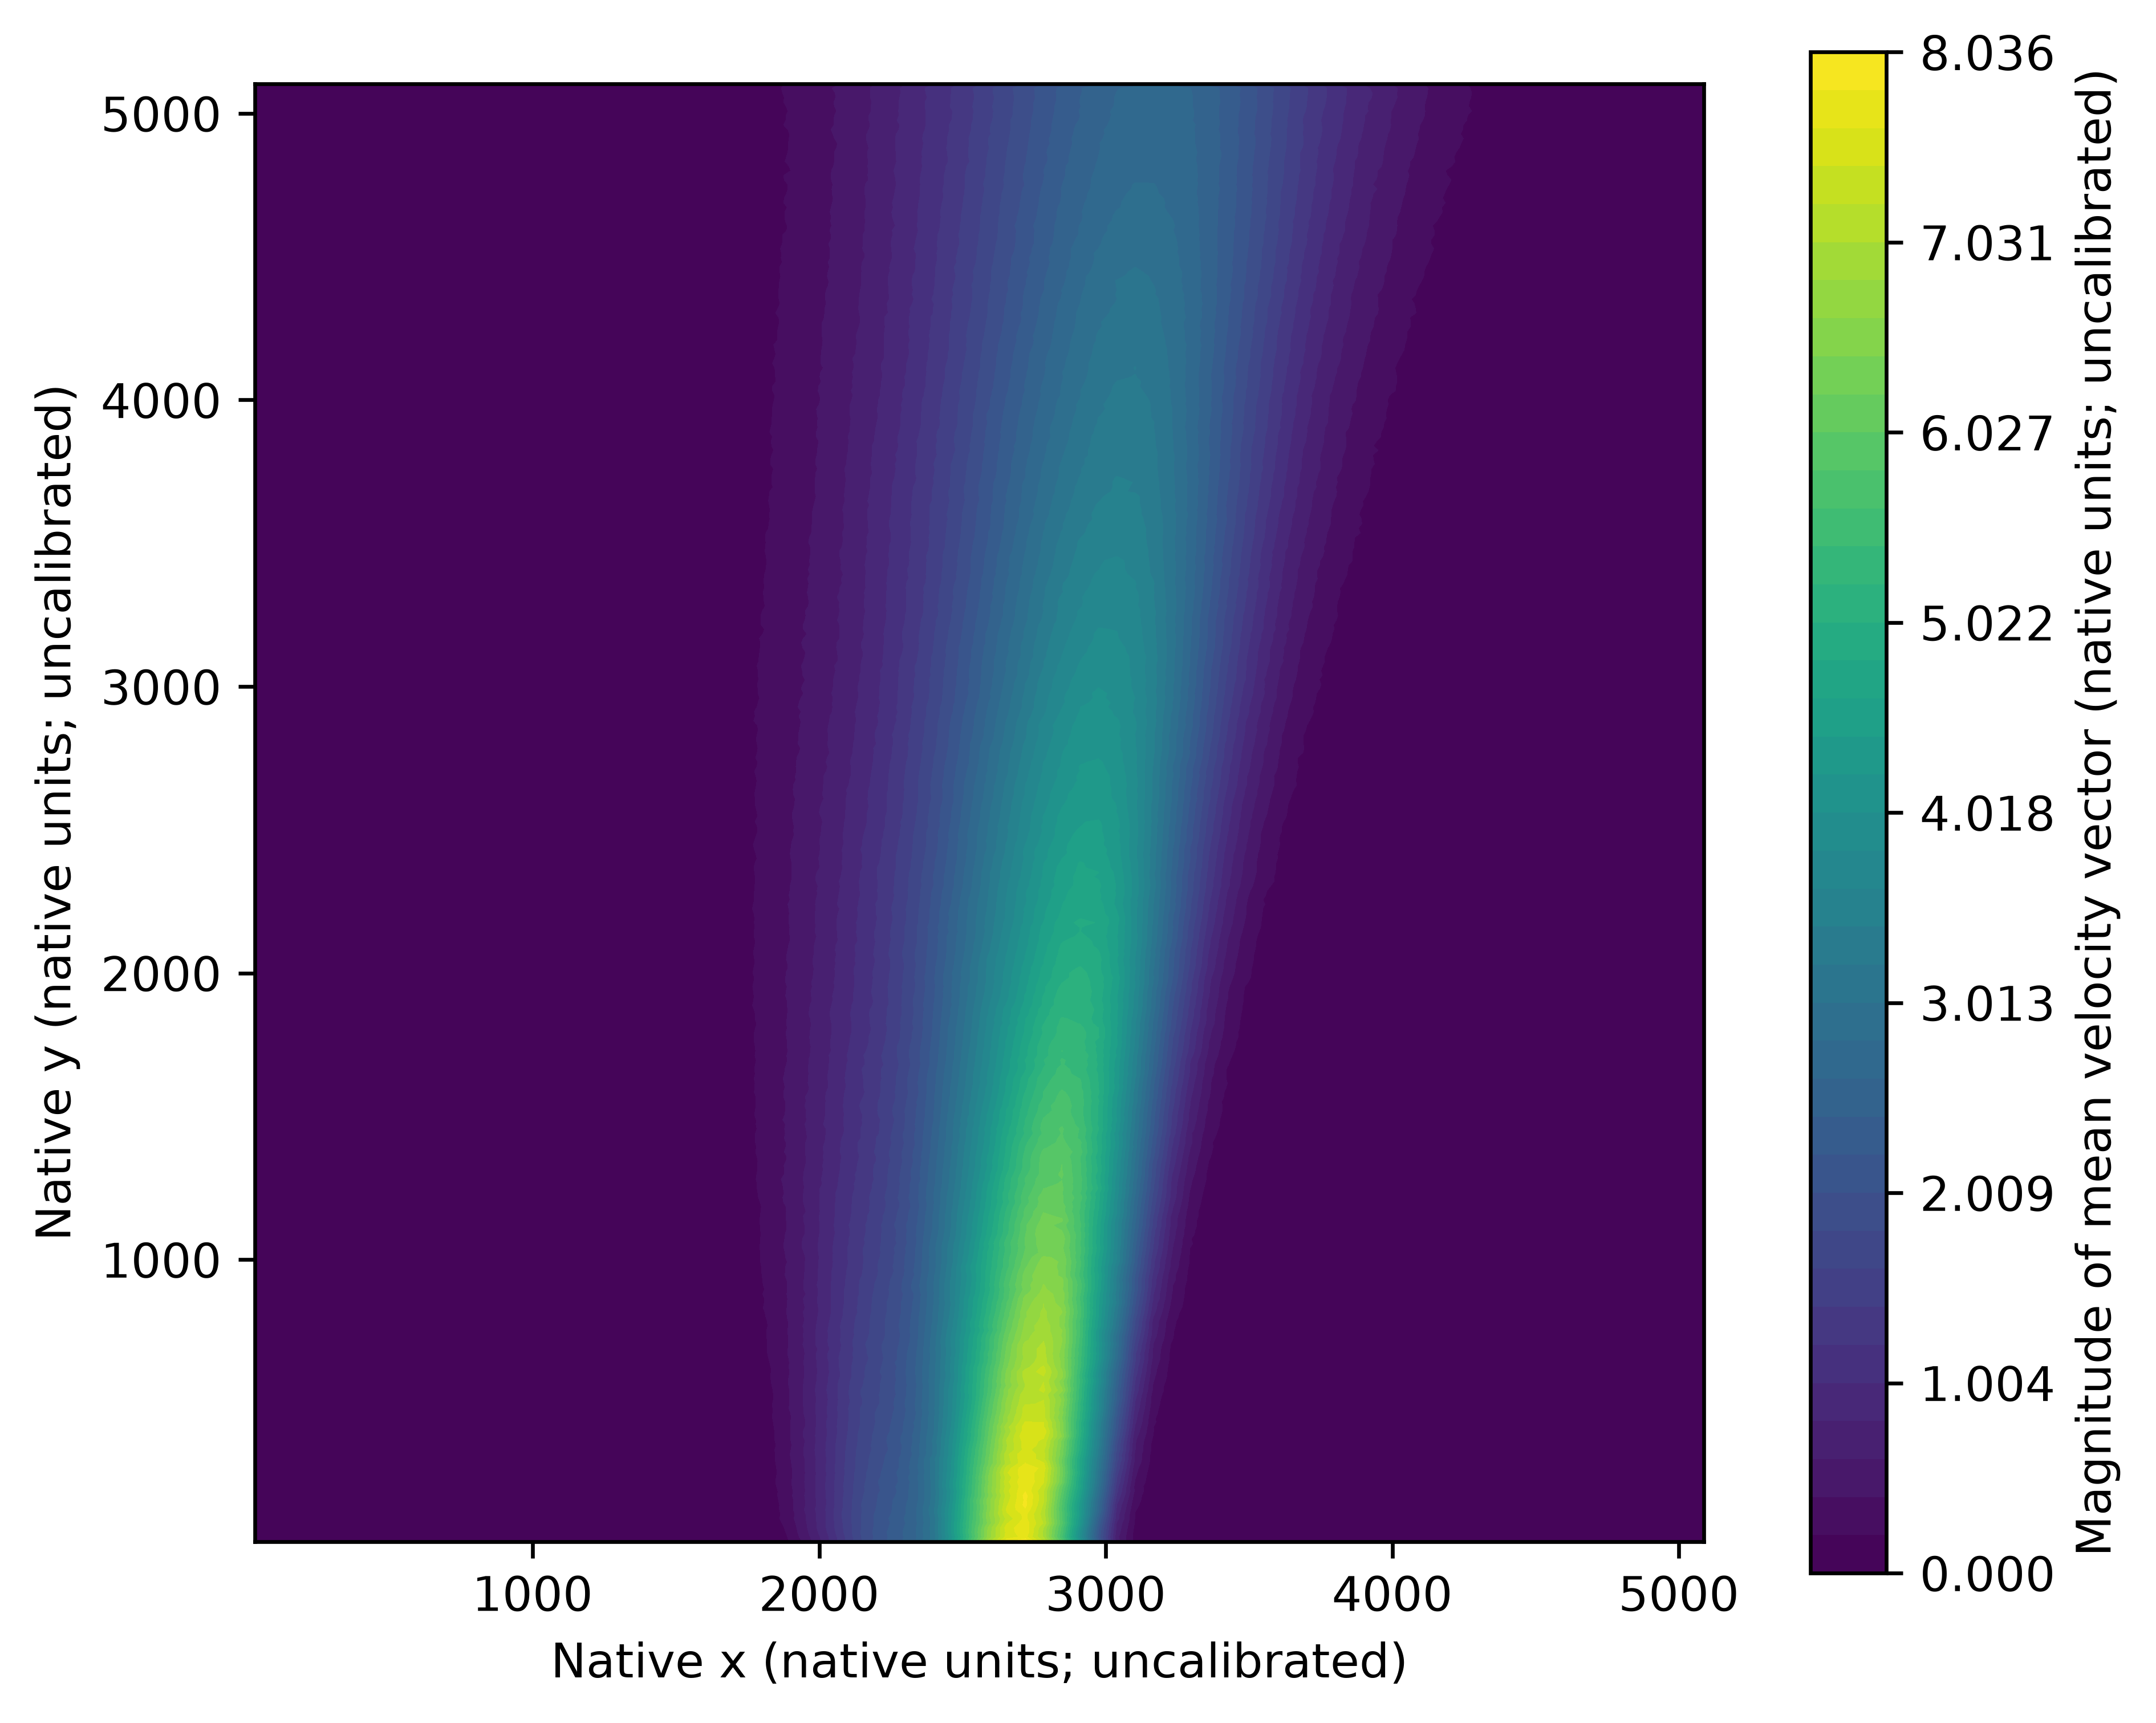

mean_instantaneous_speed


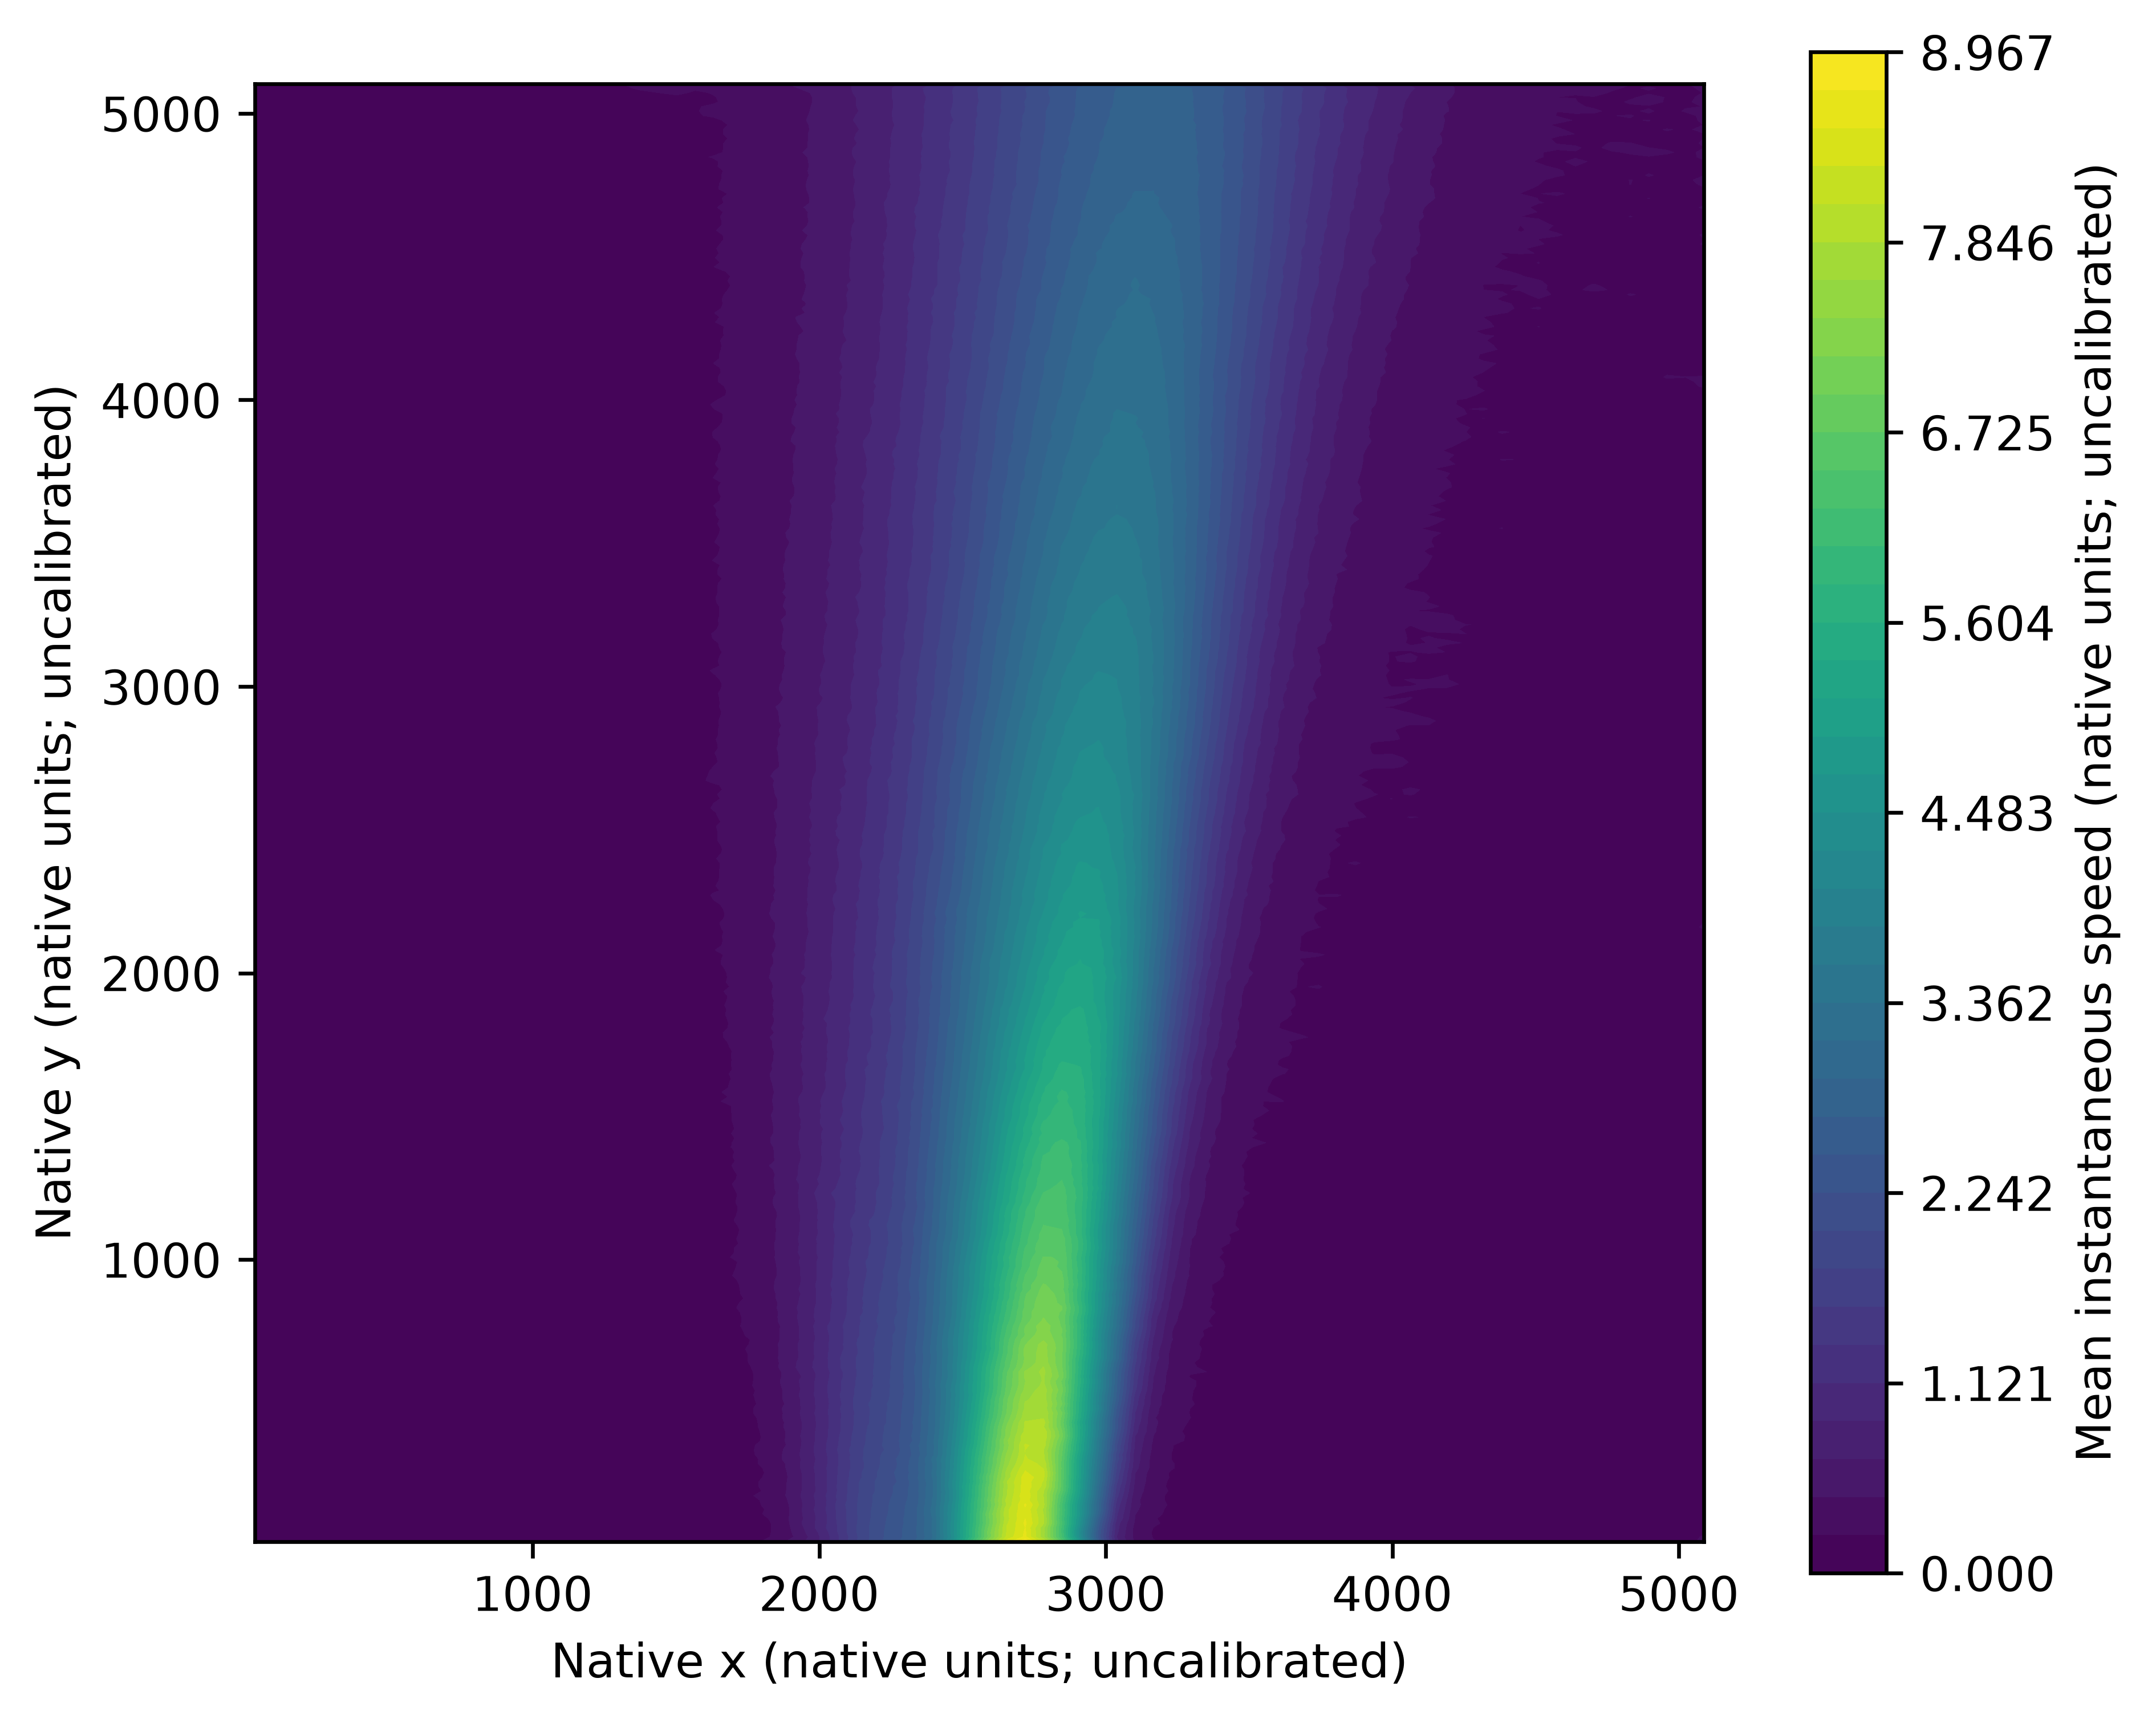

rms_u


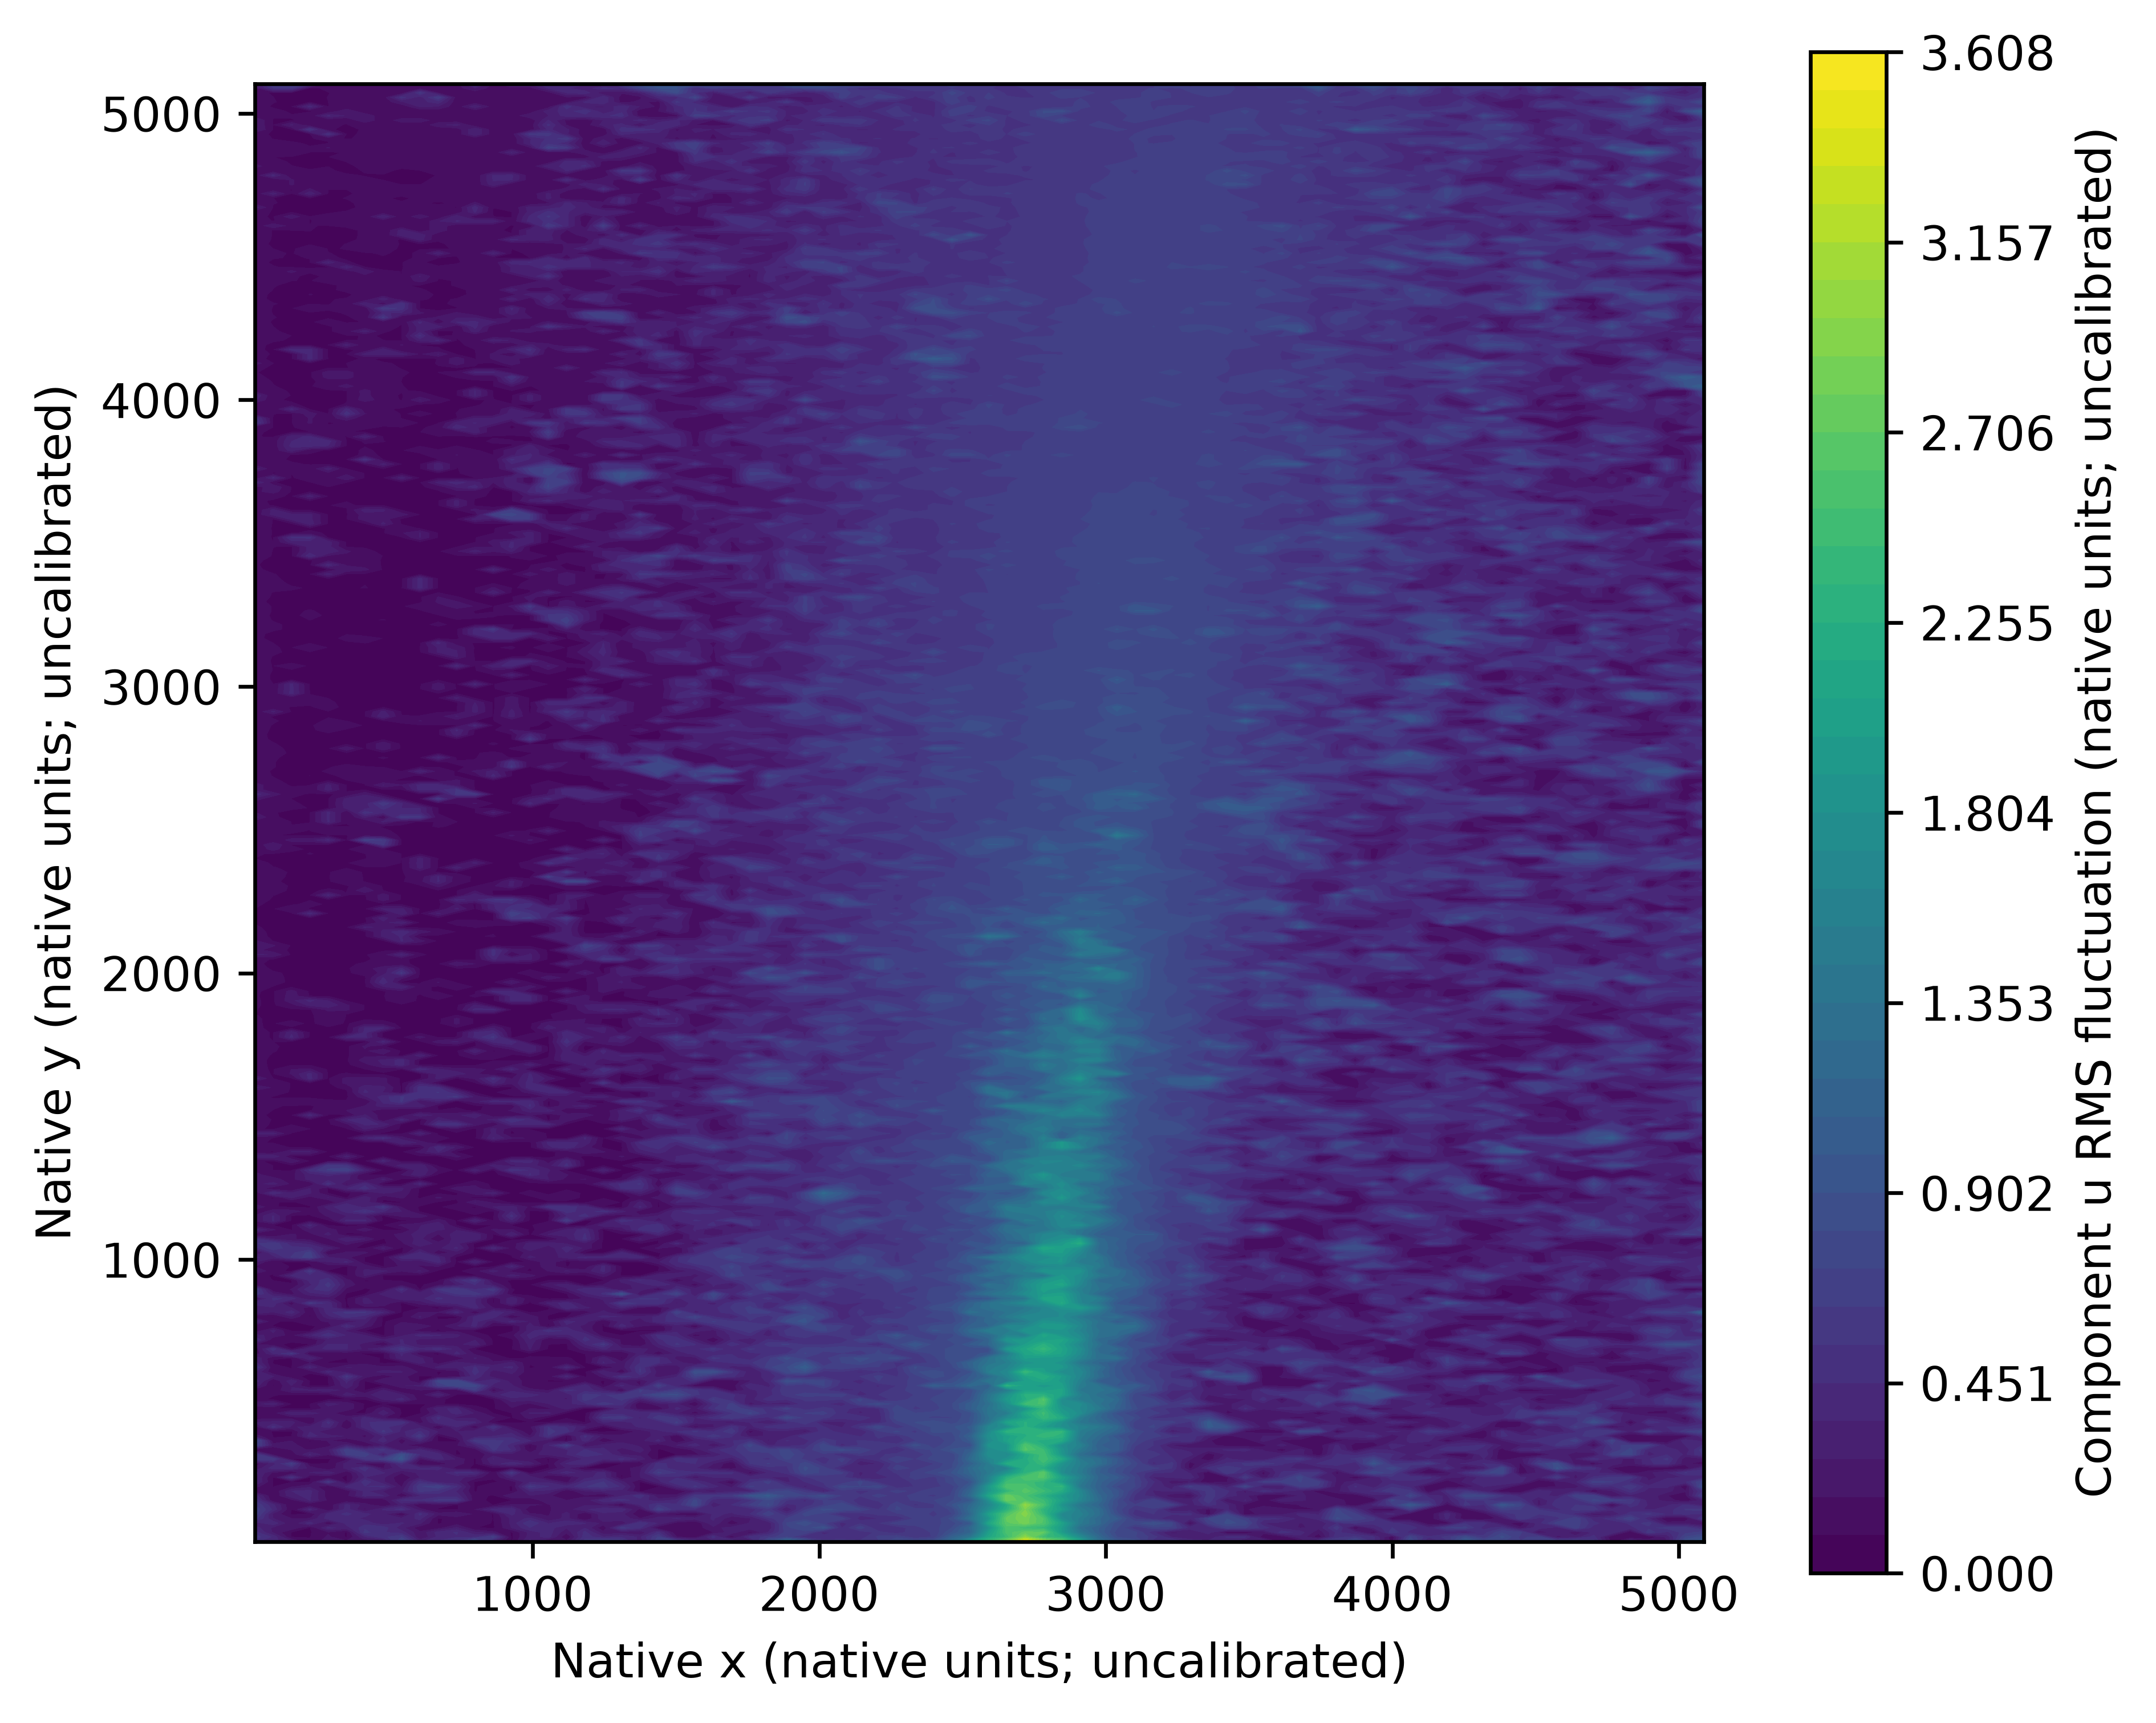

rms_v


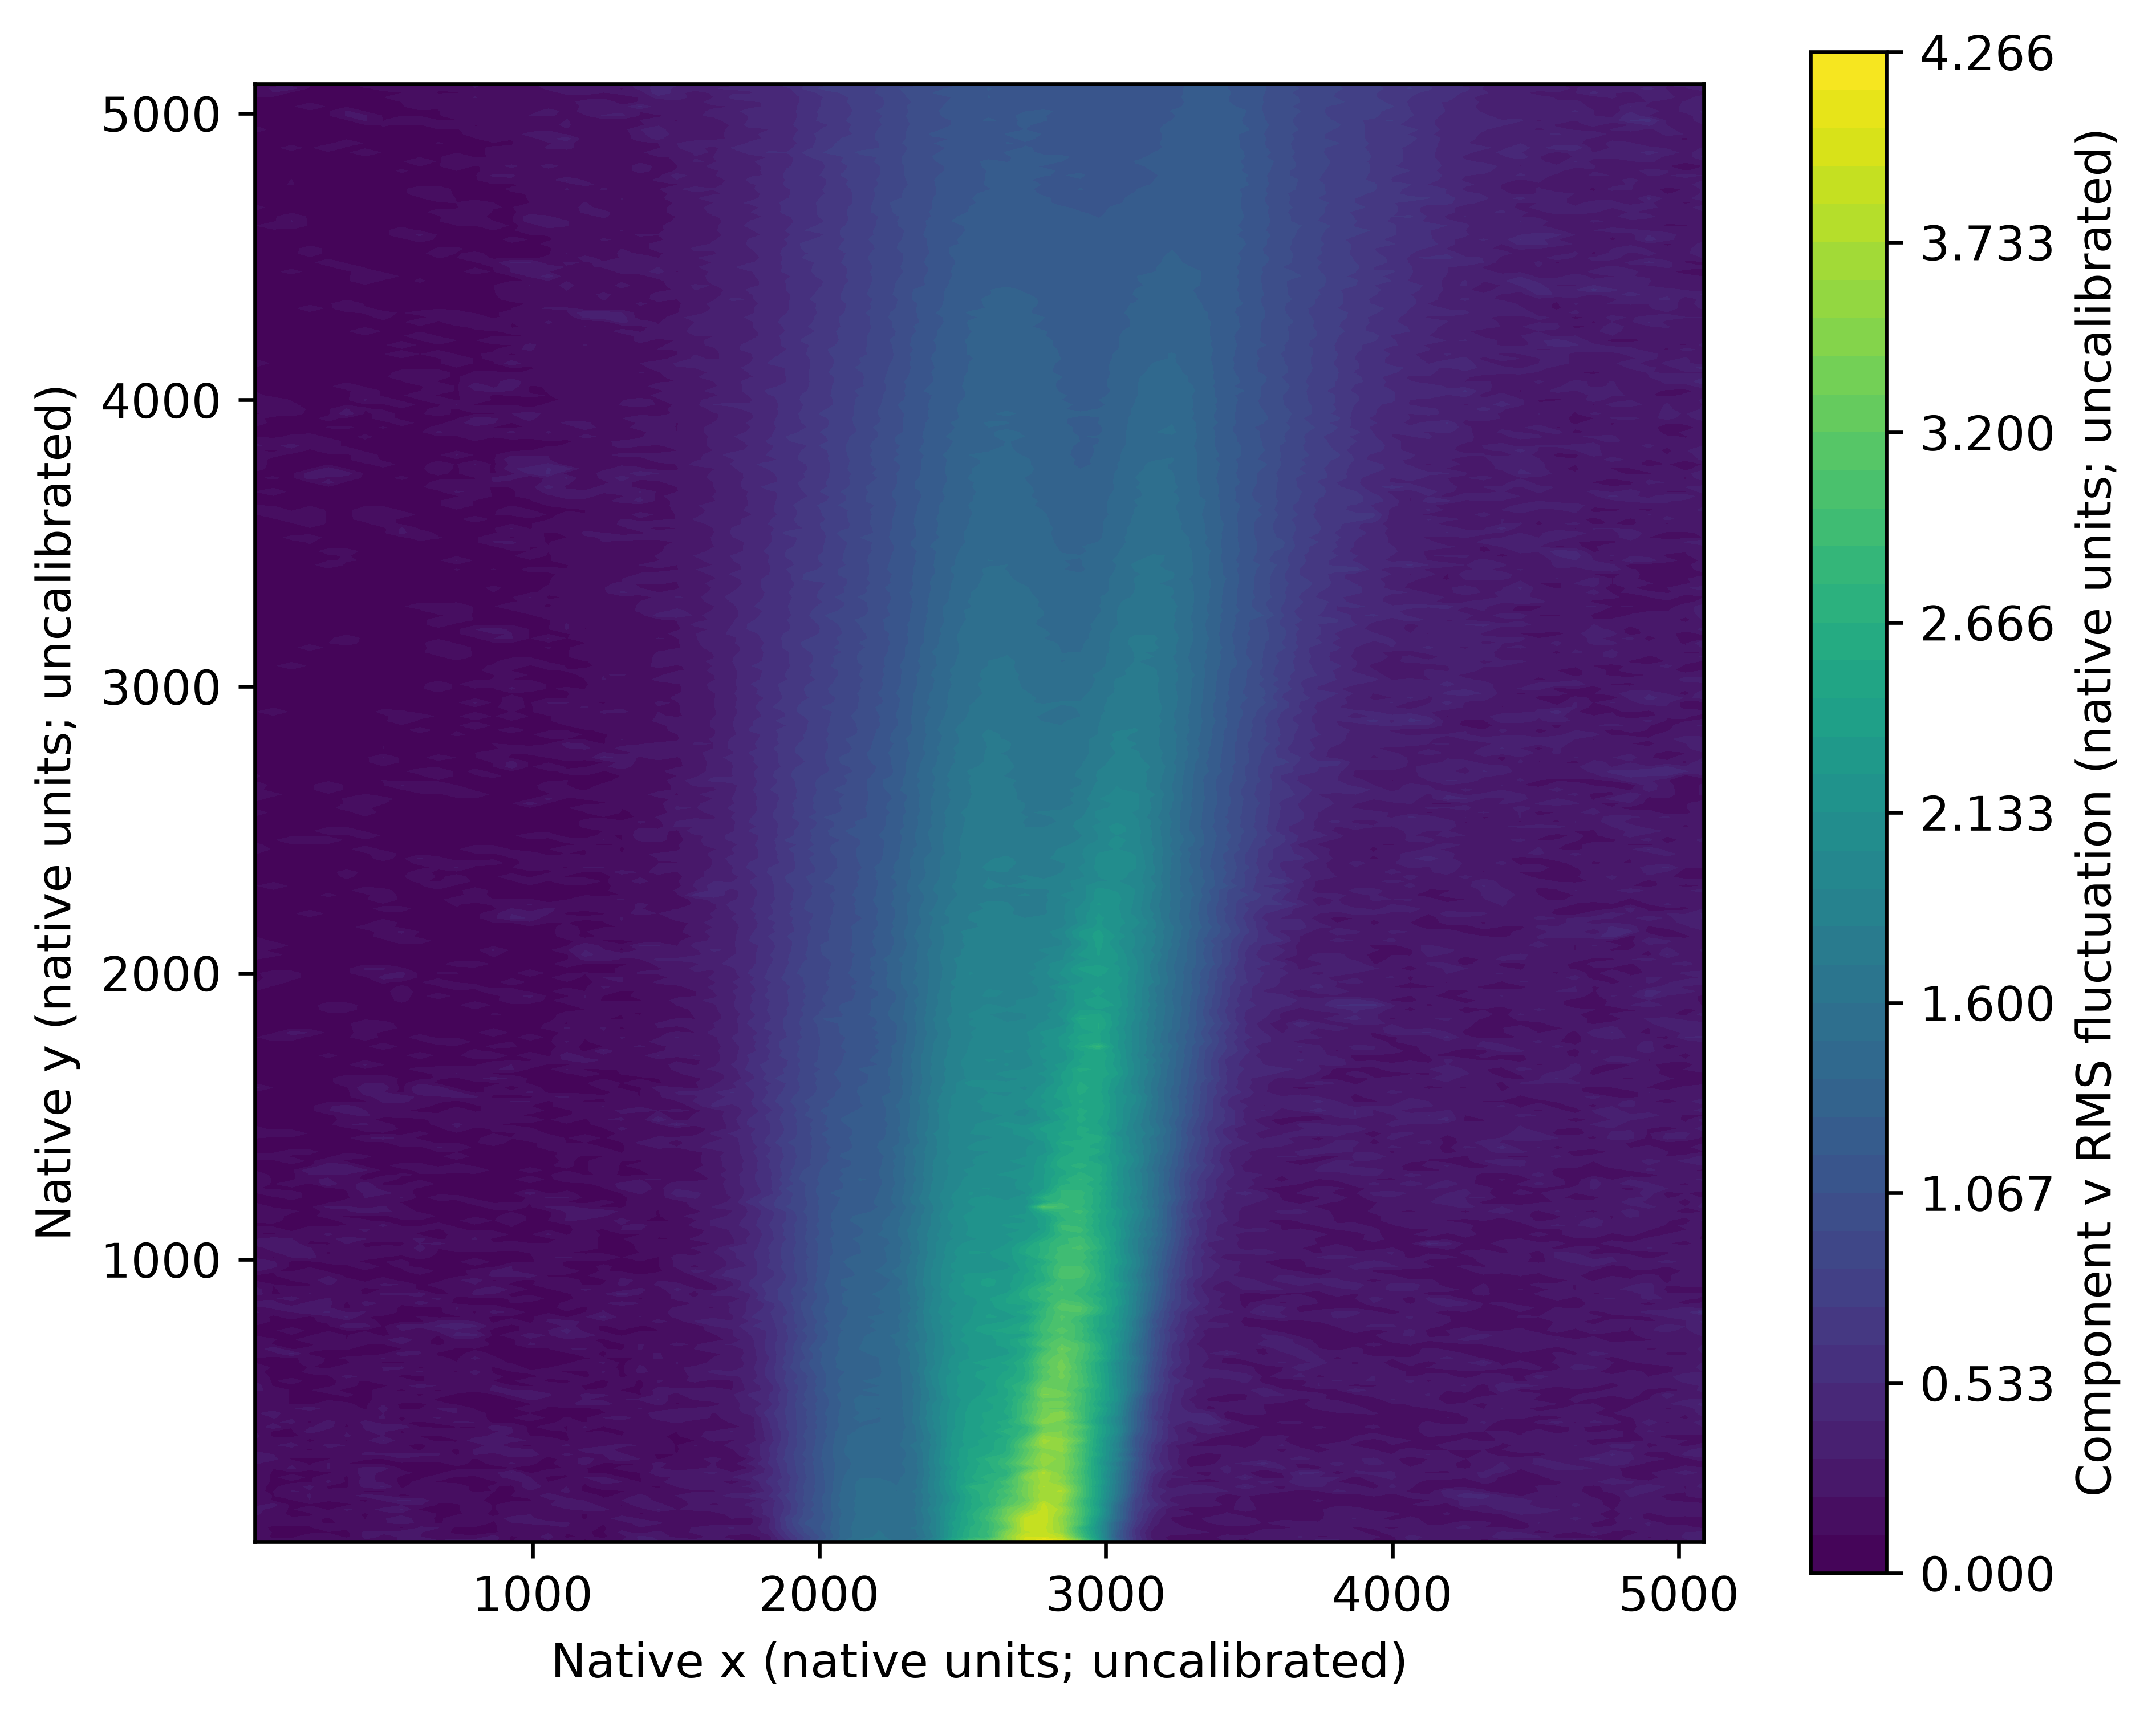

covariance


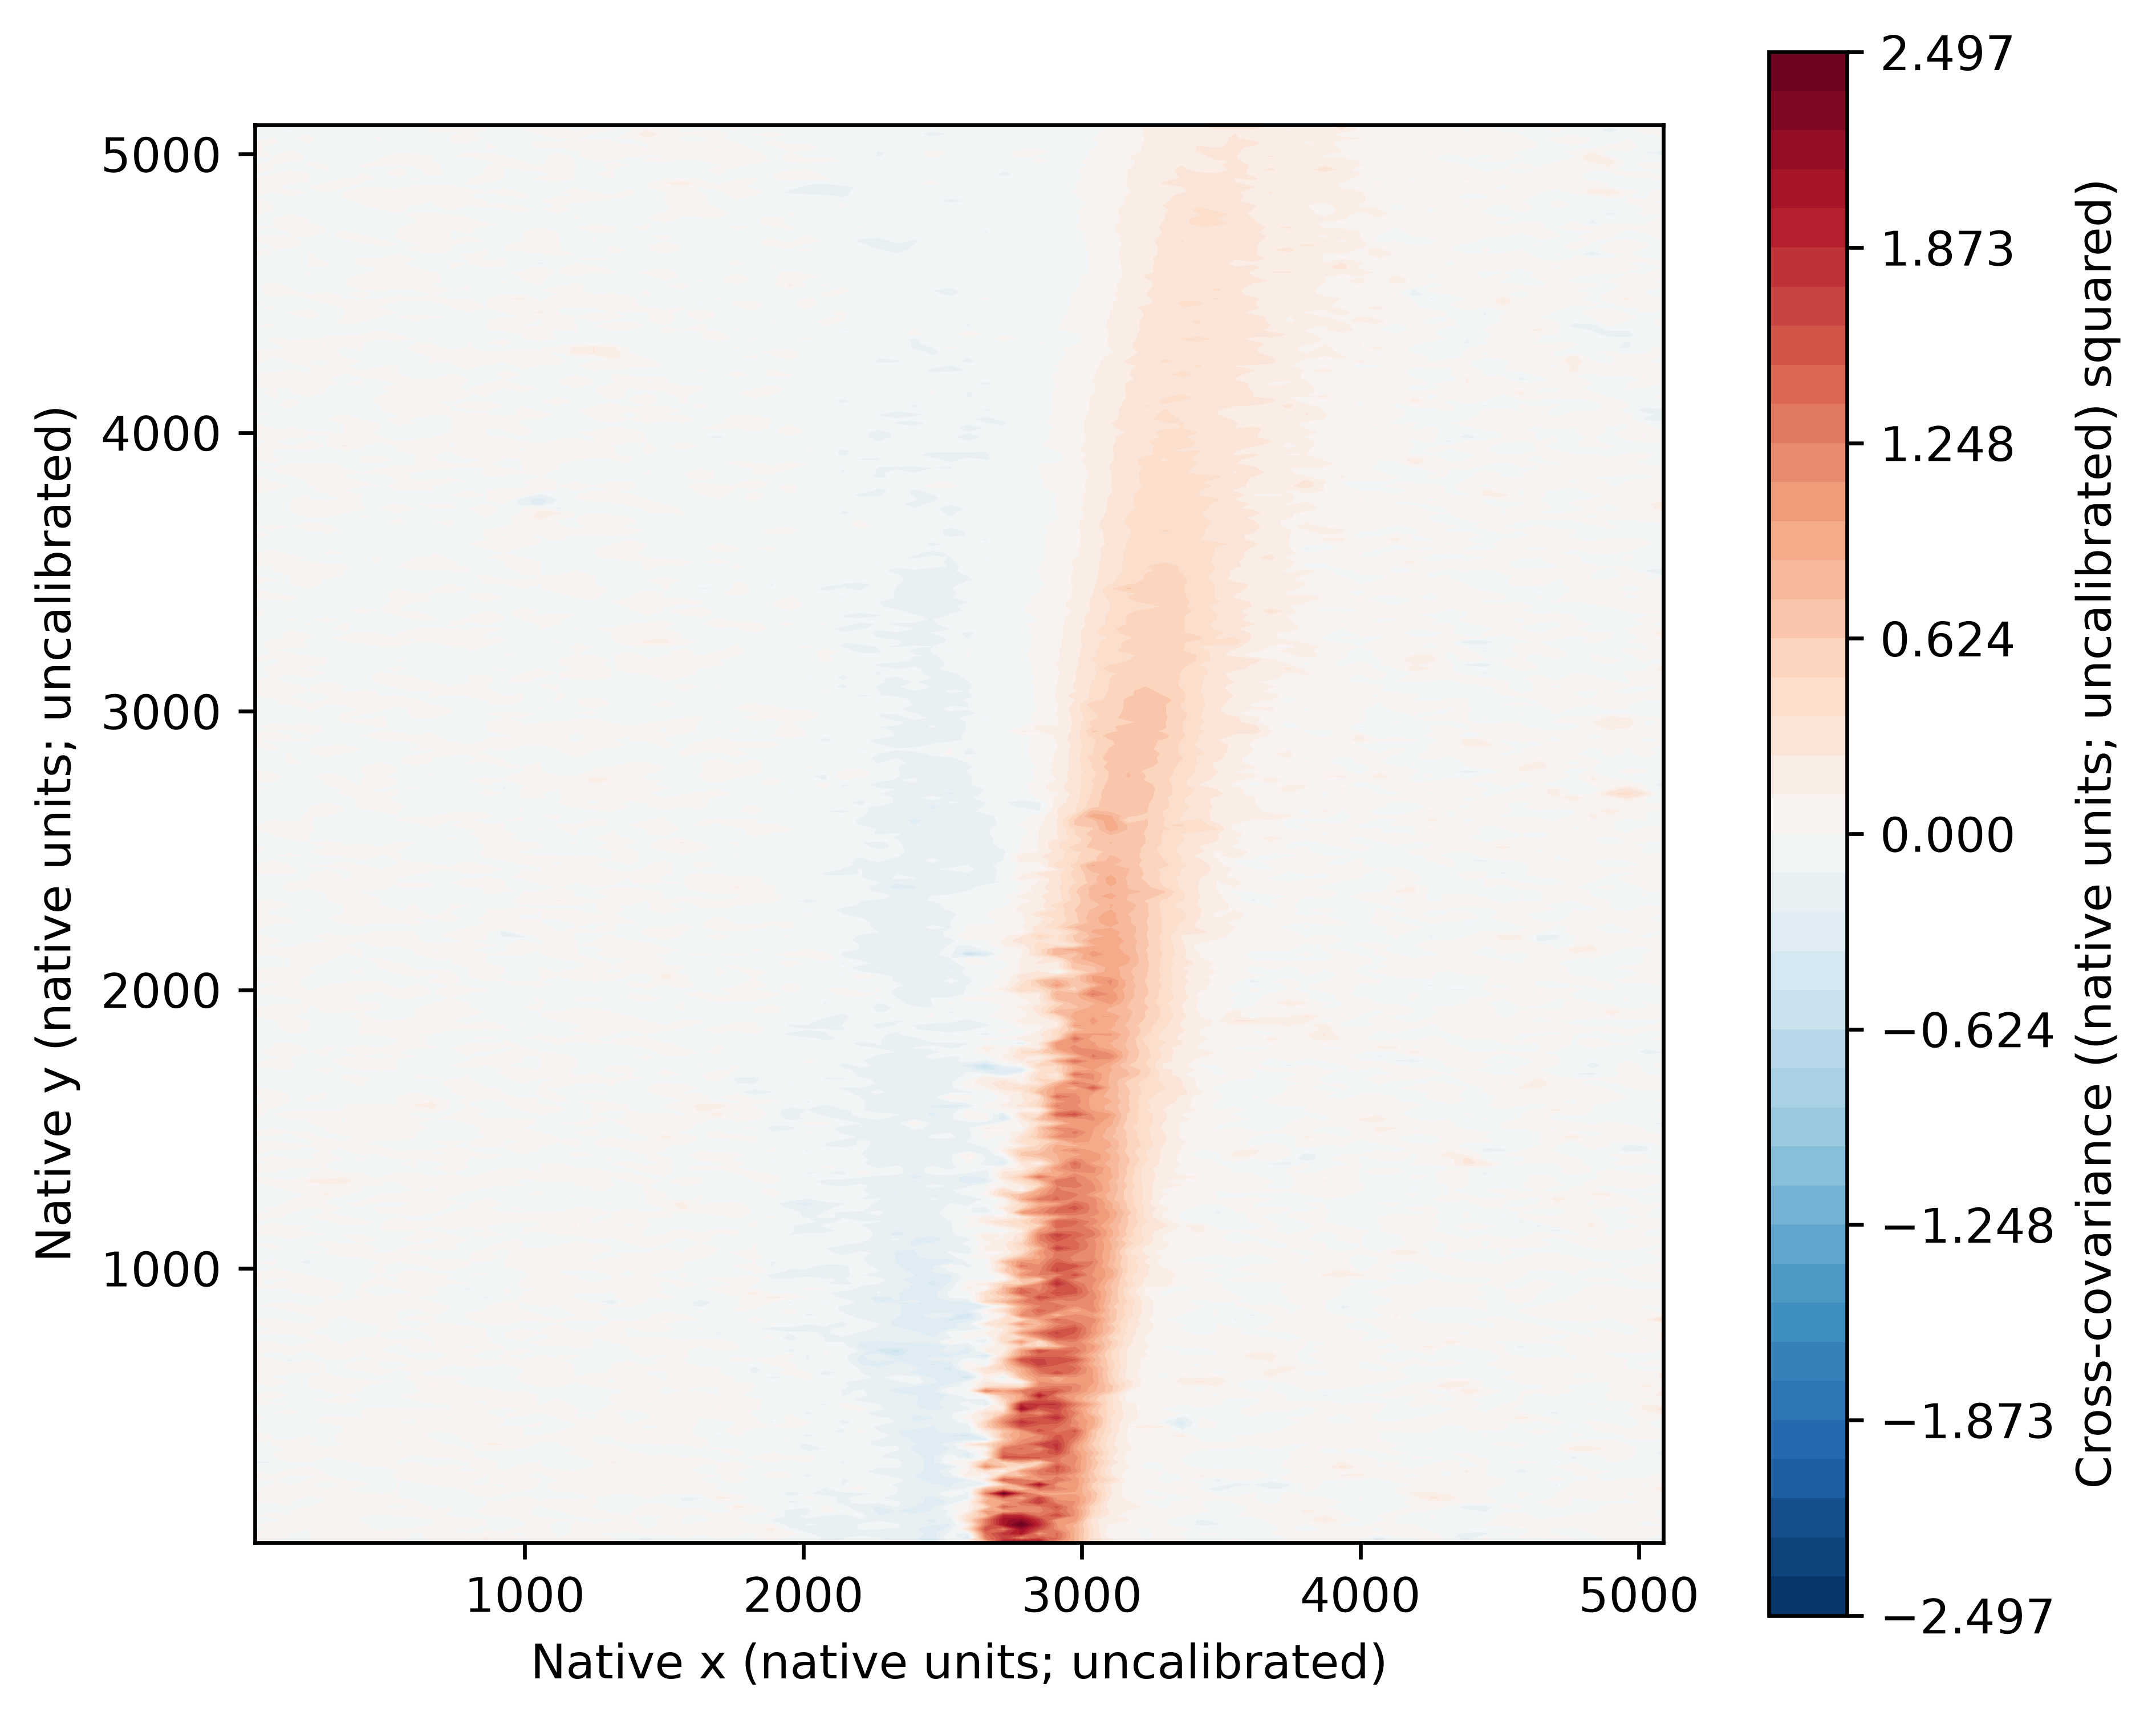

correlation


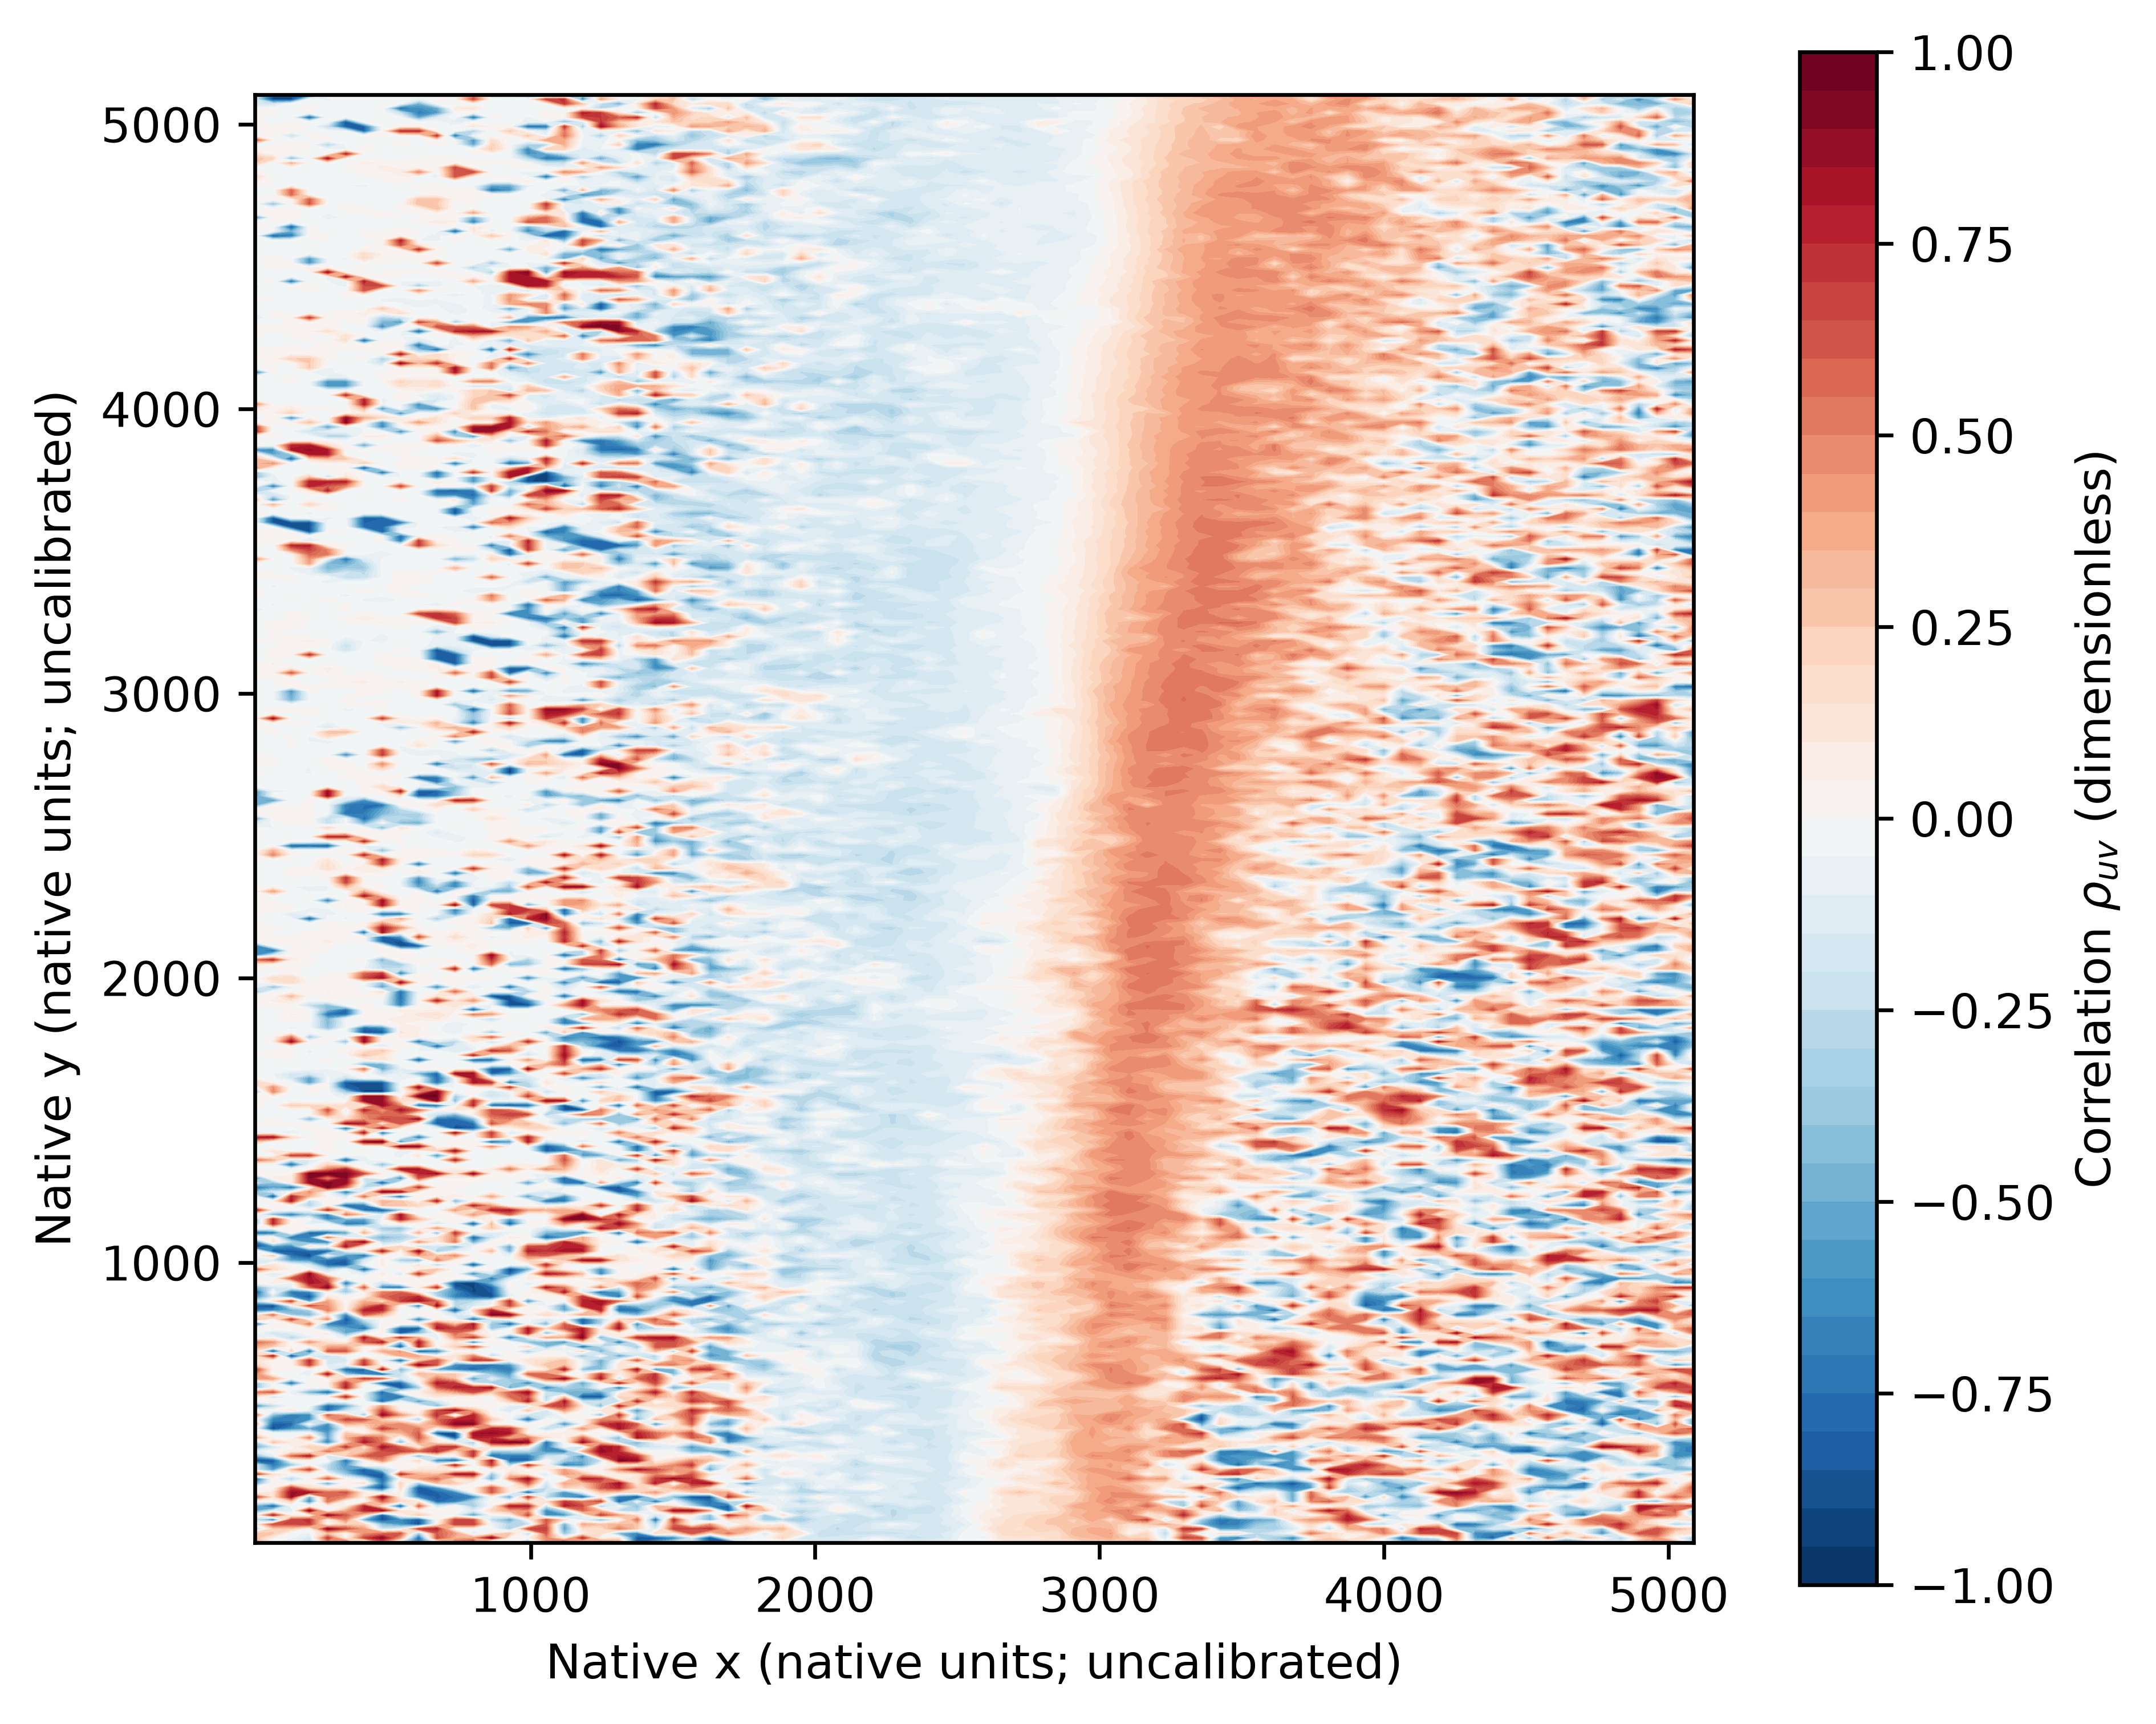

finite_pair_fraction


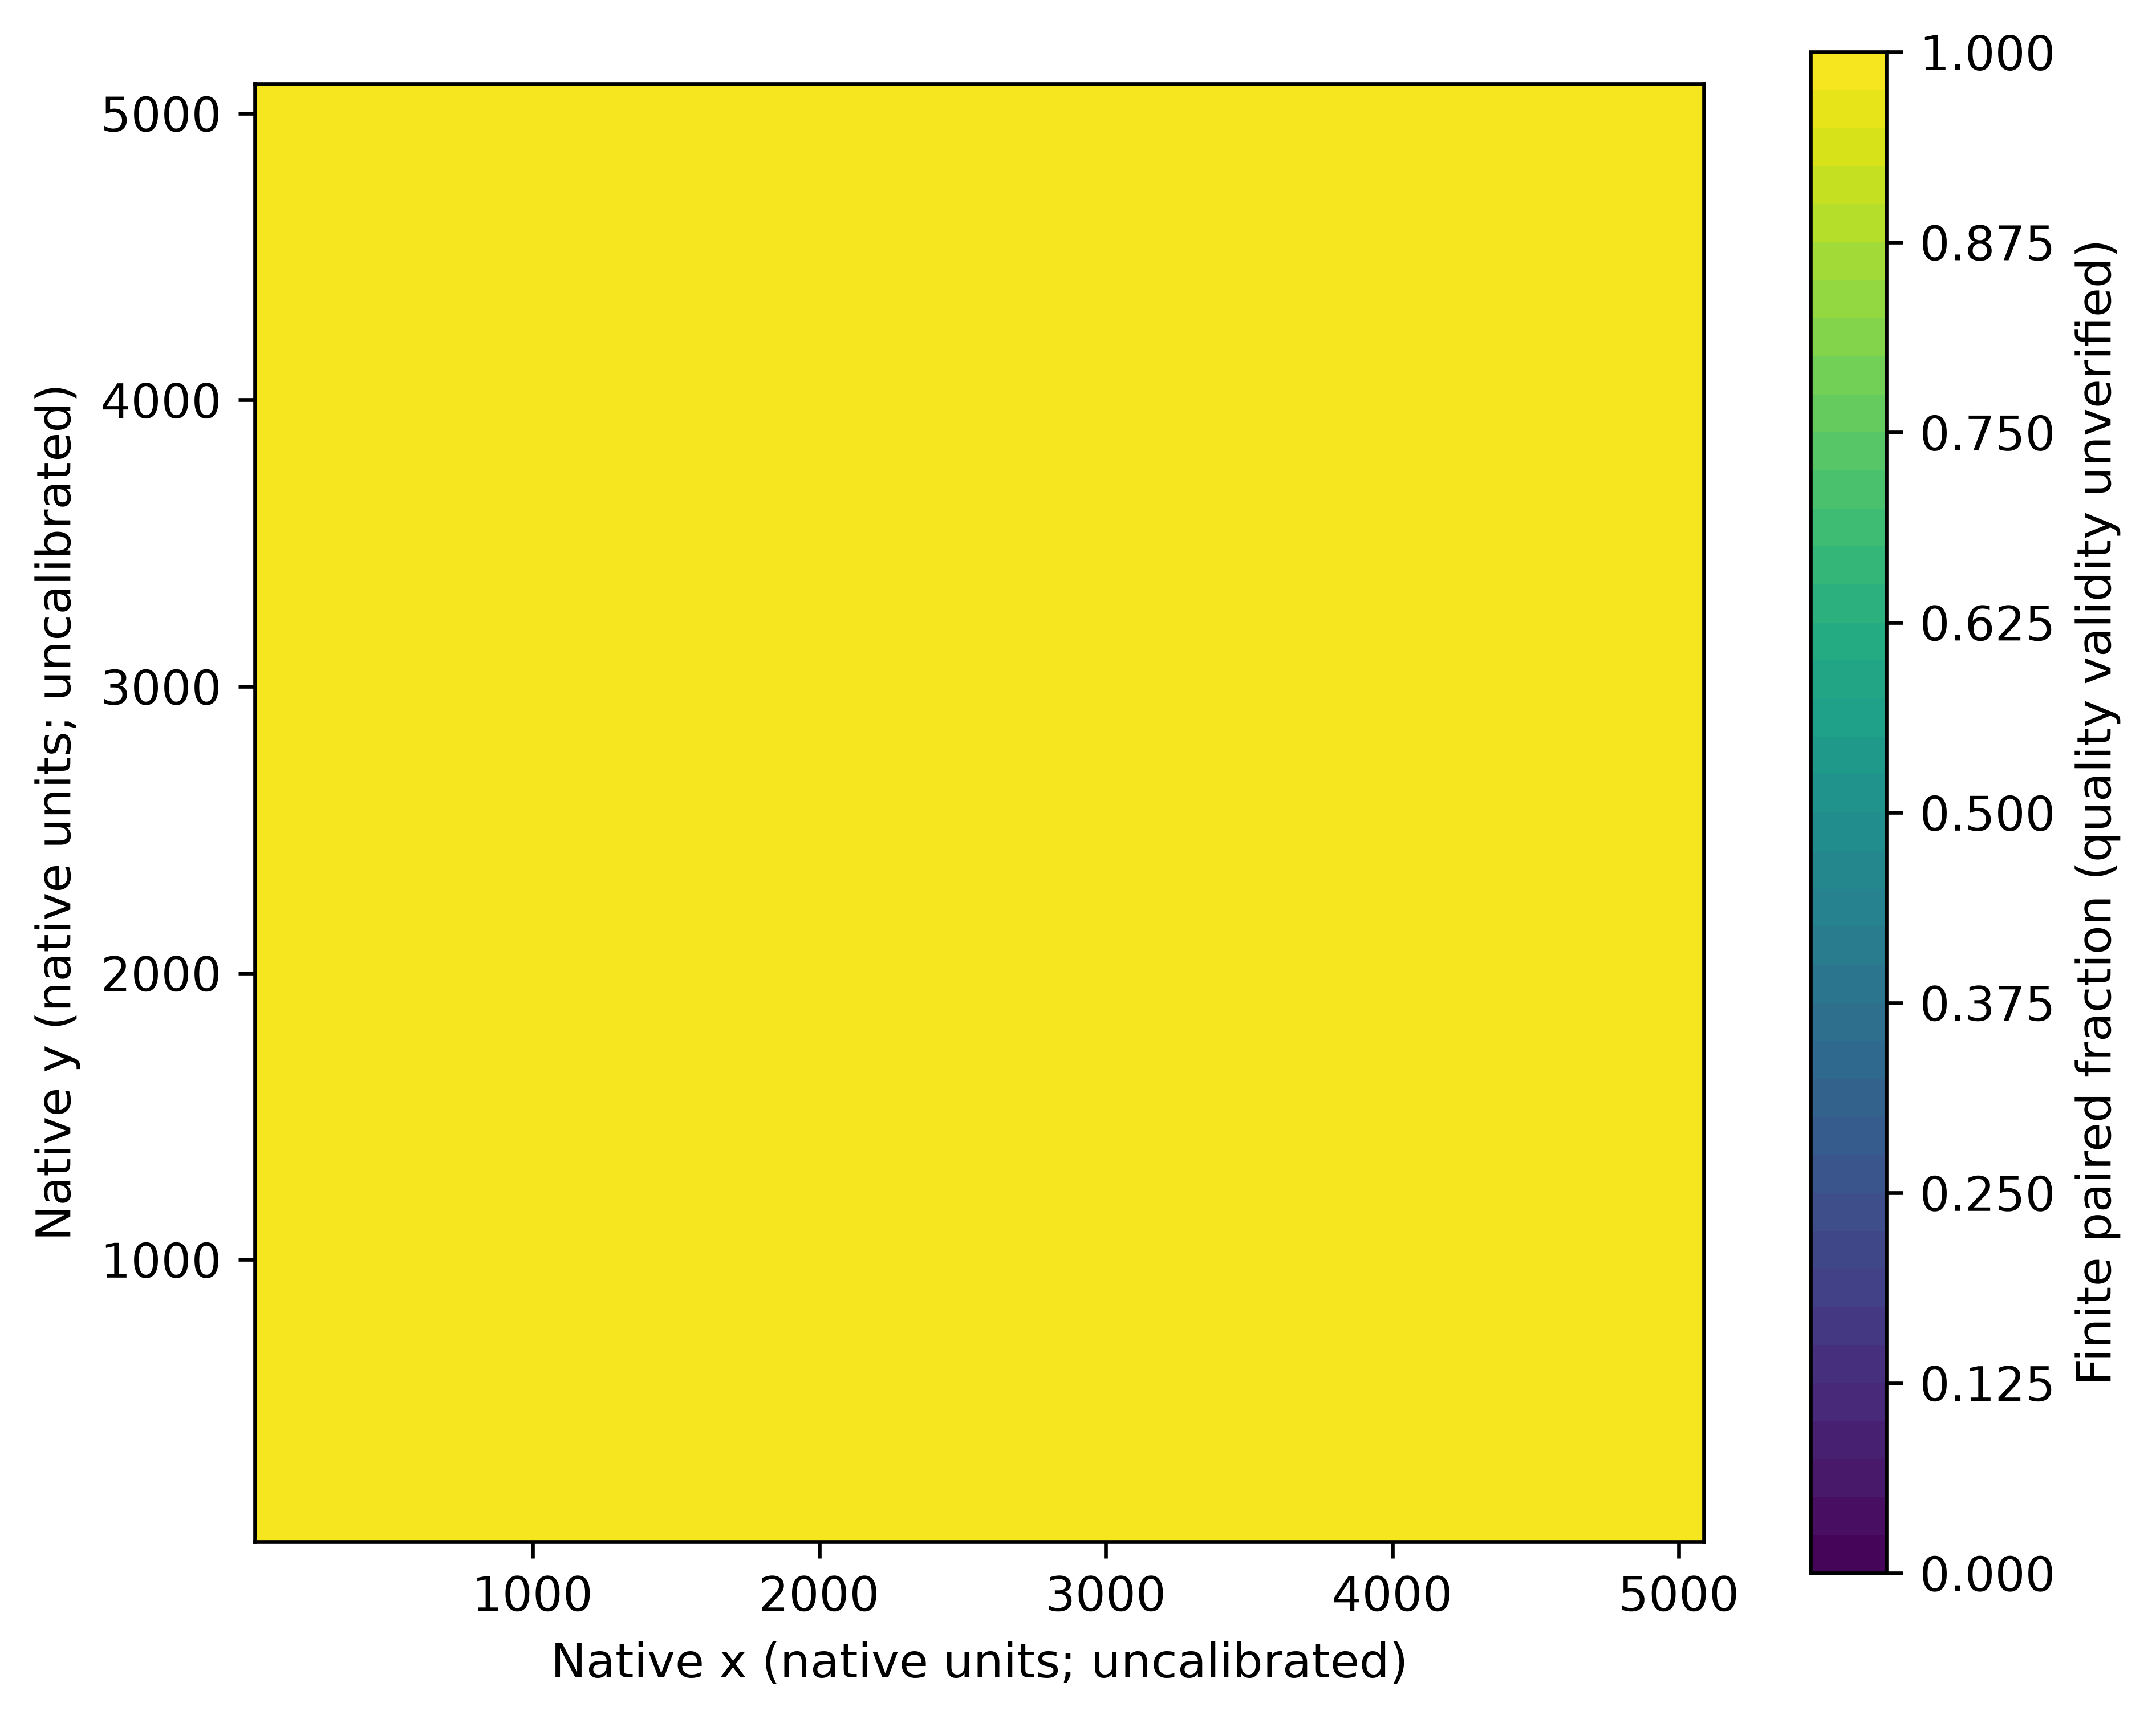

flag_0_fraction


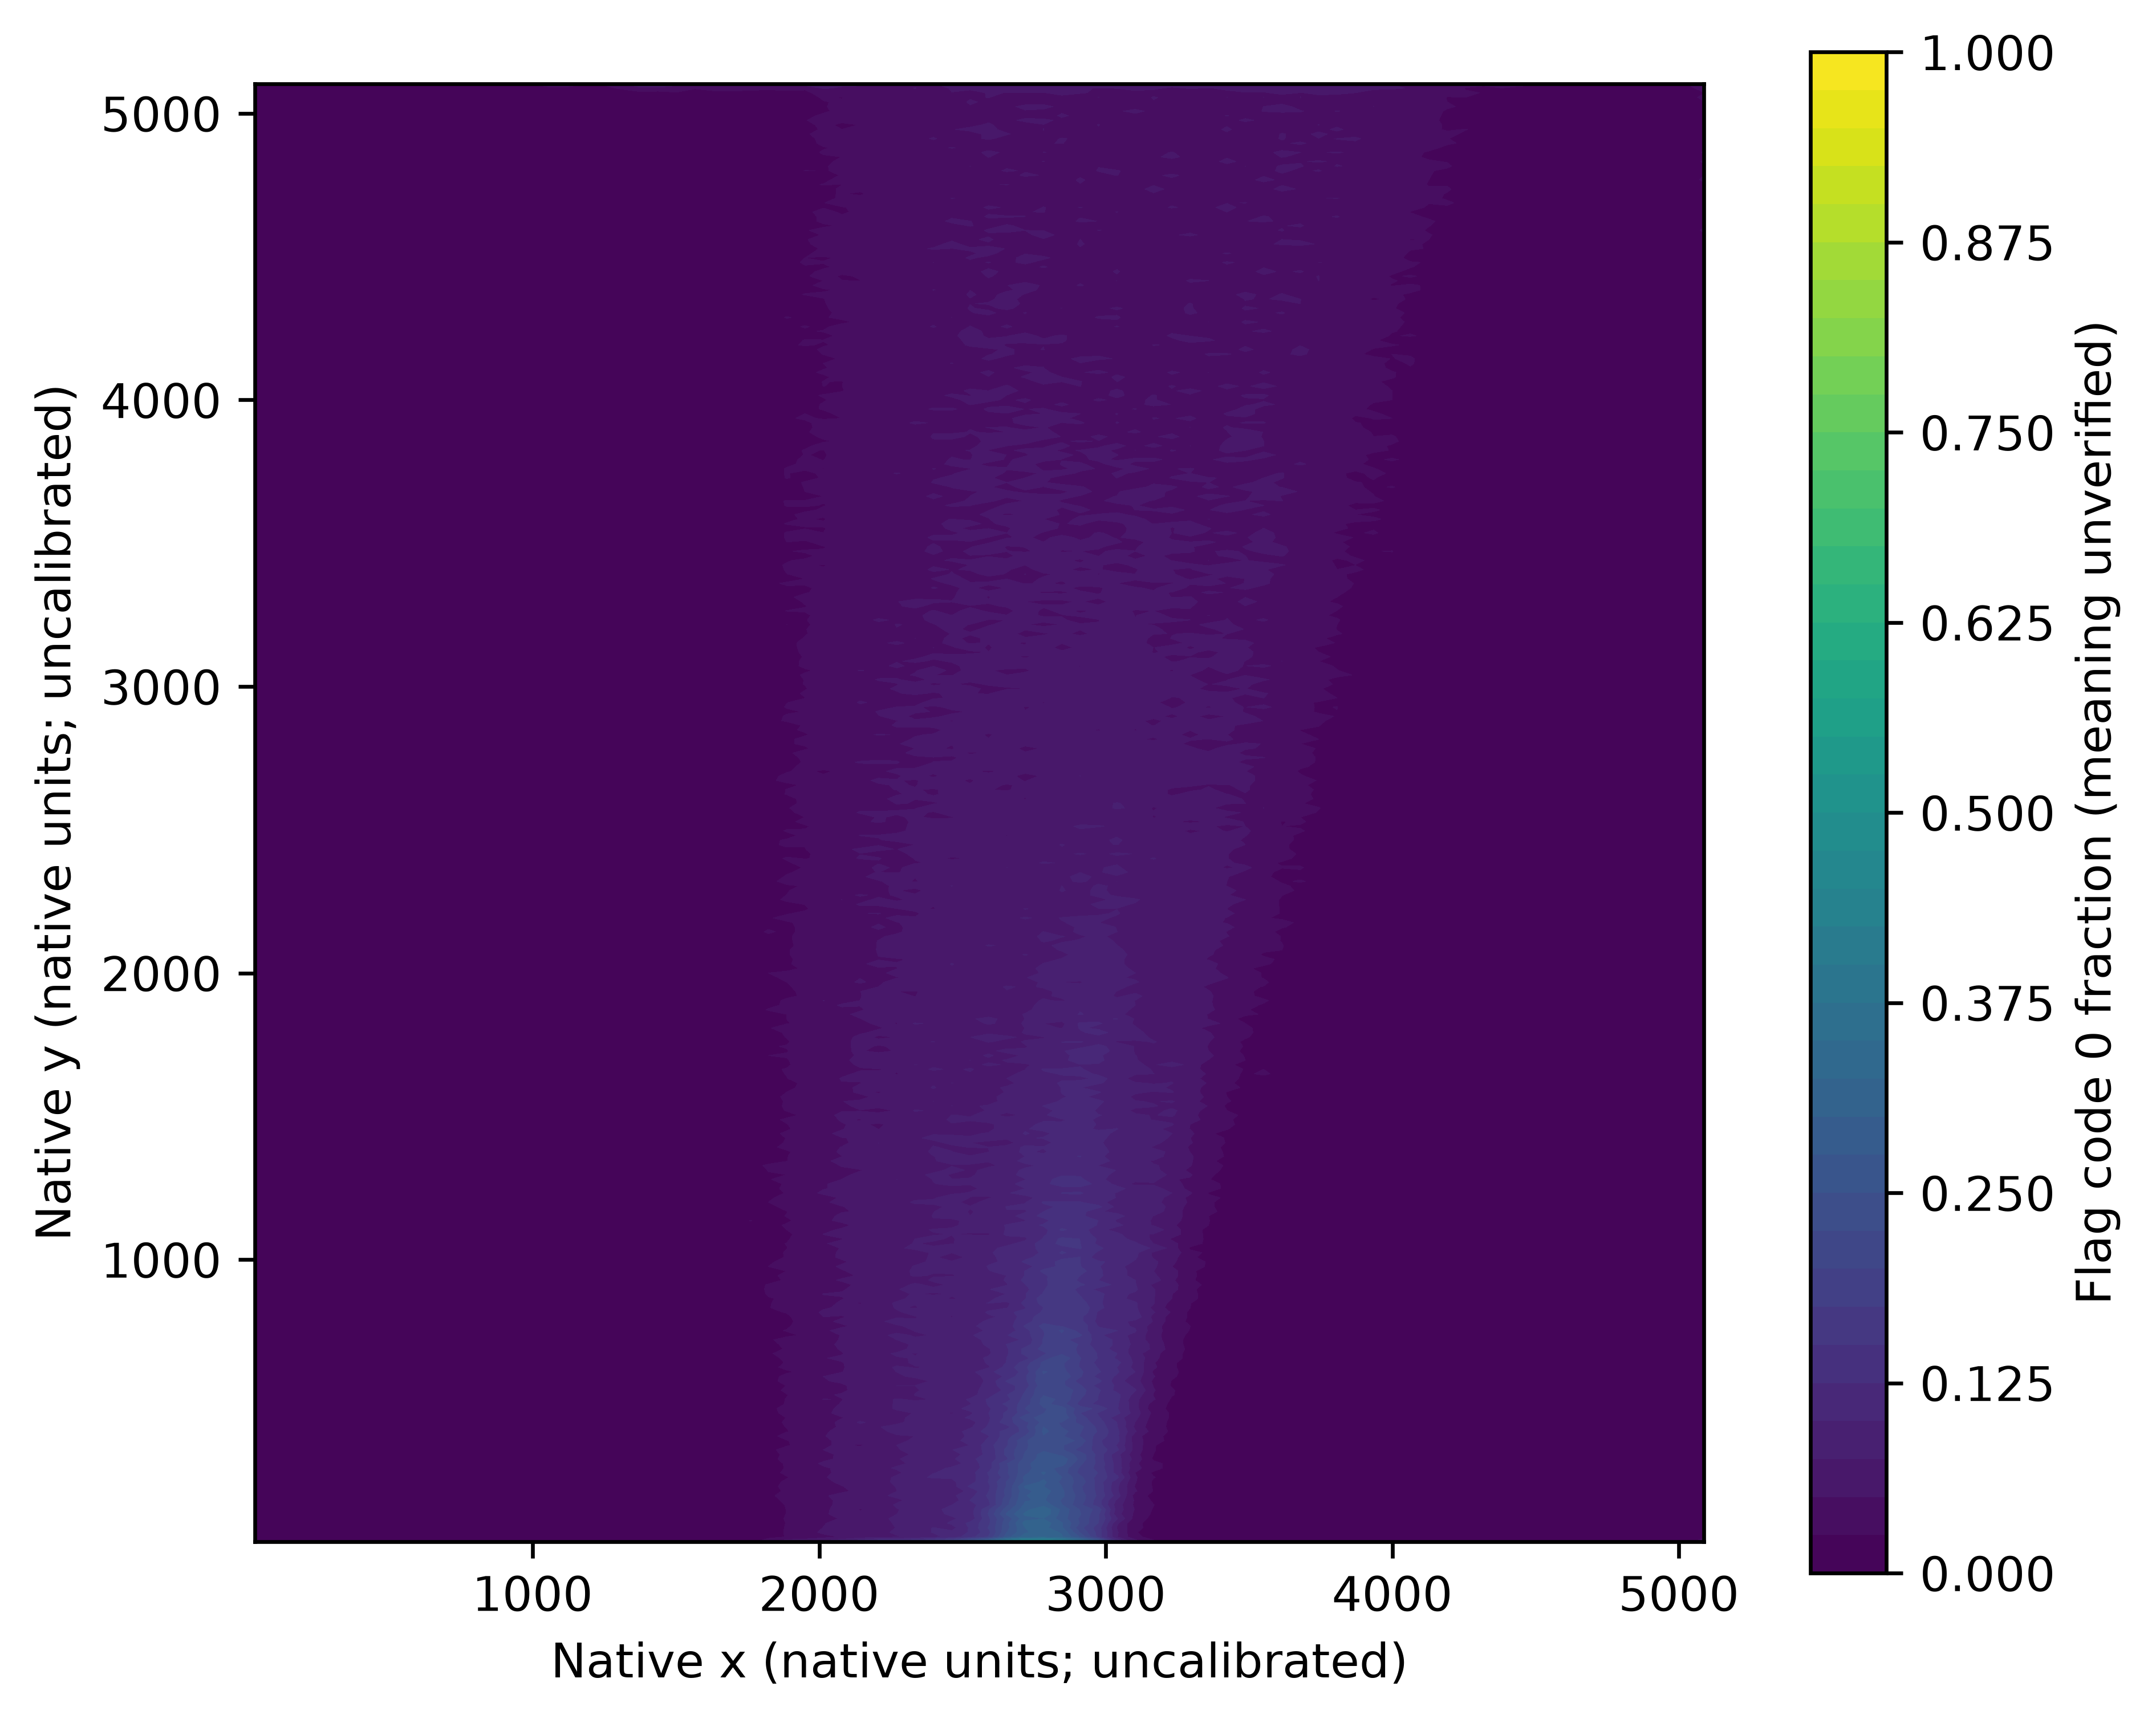

In [2]:
from IPython.display import display, Image
import json
out = root / 'PZT_Atomiser_Analysis'
for cid, r in results.items():
    print(cid, json.dumps(r['metadata'], indent=2))
    folder = out / 'diagnostics/uncalibrated' / cid
    for quantity in ['mean_u', 'mean_v', 'magnitude_mean_vector',
                     'mean_instantaneous_speed', 'rms_u', 'rms_v',
                     'covariance', 'correlation', 'finite_pair_fraction',
                     'flag_0_fraction']:
        print(quantity)
        display(Image(filename=str(folder / (quantity + '.png')), width=650))


## Reuse and remaining definitions

Edit config/analysis.json for another condition and rerun the notebook.
Coordinate and velocity scale factors must follow the verified exporter
convention. The factor 0.202 applies only if u/v are pixel displacements per
pair. Physical axial/transverse mapping requires original image orientation.
Flag selection requires a documented definition source. See ../README.md.
